In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

### Merging evaluation systems results

In [2]:
# Repository root: the first folder with settings.gradle.kts, from the working directory up
repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "settings.gradle.kts").exists())

# None: the results of the current runs (results/); "paper": the archive of the paper (results/paper/); "rebuttal":
# the archive of the rebuttal (results/rebuttal/: the data of the paper and the runs of the rebuttal, as in the
# repository STGraph-evaluation)
archive = "rebuttal"
statistics_path = os.path.join(repo_root, "results", archive) if archive else os.path.join(repo_root, "results")

query_statistics_output_file  = os.path.join(statistics_path, "query_statistics.csv")
ingestion_statistics_output_file = os.path.join(statistics_path, "ingestion_statistics.csv")

figures_path = os.path.join(repo_root, "evaluation", "figures", archive or "current")
os.makedirs(figures_path, exist_ok=True)

# numMachines of the single-machine ingestion runs: -1 in the archives (as in the paper), 1 in the current runs
single_machine = -1 if archive else 1

In [3]:
ingestion_statistics = pd.DataFrame()
query_statistics = pd.DataFrame()
for evaluated_system in os.listdir(statistics_path):
    # The archives (results/paper, results/rebuttal) are not results of the current runs
    if os.path.isdir(os.path.join(statistics_path, evaluated_system)) and evaluated_system not in ("paper", "rebuttal"):
        ingestion_file = os.path.join(statistics_path, evaluated_system, "ingestion_time","ingestion_statistics.csv")
        # Python evaluation (query_evaluation/statistics.csv) or Kotlin mains (query_time/query_statistics.csv)
        query_files = [os.path.join(statistics_path, evaluated_system, "query_evaluation","statistics.csv"),
                       os.path.join(statistics_path, evaluated_system, "query_time","query_statistics.csv")]
        query_file = next((f for f in query_files if os.path.exists(f)), None)

        if os.path.exists(ingestion_file):
            ingestion_statistics = pd.concat([ingestion_statistics, pd.read_csv(ingestion_file)], ignore_index=True)
        if query_file is not None:
            query_statistics = pd.concat([query_statistics, pd.read_csv(query_file)], ignore_index=True)

ingestion_statistics["datasetSize"] = ingestion_statistics["datasetSize"].apply(lambda x: str.capitalize(x))
# Timestamps in seconds (Python evaluation, old STGraph runs) or in milliseconds (Kotlin mains)
timestamp_to_ms = np.where(ingestion_statistics["startTimestamp"] > 1e11, 1, 1000)
ingestion_statistics["elapsedTime"] = (ingestion_statistics["endTimestamp"] - ingestion_statistics["startTimestamp"]) * timestamp_to_ms
query_statistics["datasetSize"] = query_statistics["datasetSize"].apply(lambda x: str.capitalize(x))

ingestion_statistics.to_csv(ingestion_statistics_output_file, index=False)
query_statistics.to_csv(query_statistics_output_file, index=False)

# query_statistics

Utils

In [4]:
query_names = {
    "EnvironmentCoverage": "Q1",
    "EnvironmentAggregate": "Q2",
    "MaintenanceOwners": "Q3",
    "EnvironmentAlert": "Q4",
    "EnvironmentOutlier": "Q4",
    "AgentOutlier": "Q5",
    "AgentHistory": "Q6"
}

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
patterns = ['solid', '...', '///', '/', '|', '-', '+', 'x', 'o', 'O', '.', '*']              # hatch patterns for consistency

## Generating figures

In [5]:
import matplotlib as mpl
font = 16
colors = [ 'skyblue', 'salmon', 'lightgreen', 'orange', 'violet', 'lightsteelblue', 'gold', 'crimson', 'darkgreen', 'navy', 'saddlebrown', 'teal', 'dimgray']
patterns = ['/', '\\', 'x', 'o', '.', '*']
dataset_order = ["Small", "Medium", "Large"] #, "Extralarge"]
legend_settings = {
    "borderpad": 0.2,          # padding inside legend box
    "labelspacing": 0.2,       # vertical space between entries
    "handlelength": 1.0,       # length of legend line
    "handletextpad": 0.3,      # space between line and text
    "borderaxespad":0.2,      # space between legend and axes
    "columnspacing":0.5,       # space between columns (if multiple columns)
    "frameon":False,
    "bbox_to_anchor":(0.5, 1.1),
    "fontsize":font,
    "loc":"upper center",
}
CLIP_VALUE = 1e6 # Valore di clipping per gestire i fuori scala (es. AeonG)
fig_x = 3
fig_y = 2.5
mpl.rcParams['font.family'] = 'Times New Roman'
tableau10 = [
    "#4E79A7",  # blue
    "#F28E2B",  # orange
    "#E15759",  # red
    "#76B7B2",  # teal
    "#59A14F",  # green
    "#EDC948",  # yellow
    "#B07AA1",  # purple
    "#FF9DA7",  # pink
    "#9C755F",  # brown
    "#BAB0AC"   # gray
]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=tableau10)

def sci_format(x):
    if pd.isna(x):
        return "--"
    if not np.isfinite(x):
        return r"$\infty$"

    if x < 0:  # esecuzioni fallite, registrate come -1
        return "--"

    if x == 0:
        return "$0$"

    exponent = int(np.floor(np.log10(x)))
    mantissa = x / (10**exponent)
    return f"${mantissa:.1f} \\cdot 10^{{{exponent}}}$"

def print_latex(grouped, pivot=["dataset", "Size"], columns="Model", scinotation=True):
    grouped["datasetSize"] = pd.Categorical(grouped["datasetSize"], categories=dataset_order, ordered=True)
    latex_df = grouped \
            .rename(columns={"datasetSize": "Size", "model": "Model", "elapsedTime": "Elapsed Time (s)", "queryid": "ID"})
    latex_df["Size"] = latex_df["Size"].cat.rename_categories({"Small": "S", "Medium": "M", "Large": "L"})
    if columns is not None:
        latex_df = latex_df.pivot(index=pivot, columns=columns, values="Elapsed Time (s)")
    else:
        latex_df = latex_df.set_index(pivot)
    if scinotation:
        latex_df = latex_df.map(sci_format)
    print(latex_df.to_latex(index=True, float_format="%.1f", escape=False).replace("NaN", "--"))

def clean_df(df, numMachines=None, threads=None):
    df.replace({"1692200": "Small", "16922000": "Medium", "9223372036854775807": "Large", "Full": "Large", "full": "Large", "PGAge": "AGTS", "pgage": "AGTS", "stgraph": "STGraph"}, inplace=True) # "Large": "Medium", "Big": "Large",
    if numMachines is not None: df = df[df["numMachines"] == numMachines]
    if threads is not None: df = df[df["threads"] == threads]
    if "tsElapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["tsElapsedTime"], errors="coerce") / 1000
    elif "elapsedTime" in df.columns:
        df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000
    # -------------------------
    # Dataset size filter
    # -------------------------
    size_order = ["Small", "Medium", "Large", "Extralarge"]
    df = df[df["datasetSize"].isin(size_order)].copy()
    df["datasetSize"] = (
        df["datasetSize"]
        .astype("category")
        .cat.set_categories(size_order, ordered=True)
    )
    if "graphElapsedTime" in df.columns and "tsElapsedTime" in df.columns:
        df["graphElapsedTime"] = df["graphElapsedTime"] / 1000  # Convert ms to seconds
        df["tsElapsedTime"] = df["tsElapsedTime"] / 1000  # Convert ms to seconds
    return df


Ingestion statistics

\begin{tabular}{llllllll}
\toprule
 & Model & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph \\
dataset & Size &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic-iv} & S & -- & $0$ & -- & -- & -- & $9.1 \cdot 10^{0}$ \\
 & M & -- & $0$ & -- & -- & -- & $8.4 \cdot 10^{1}$ \\
 & L & -- & -- & -- & -- & -- & $4.0 \cdot 10^{2}$ \\
\cline{1-8}
\multirow[t]{3}{*}{smartbench} & S & $8.4 \cdot 10^{1}$ & $0$ & $2.9 \cdot 10^{1}$ & -- & $4.3 \cdot 10^{4}$ & $1.3 \cdot 10^{1}$ \\
 & M & $6.2 \cdot 10^{2}$ & $0$ & $1.1 \cdot 10^{2}$ & -- & -- & $5.3 \cdot 10^{1}$ \\
 & L & $1.2 \cdot 10^{5}$ & -- & -- & -- & -- & $1.7 \cdot 10^{3}$ \\
\cline{1-8}
\bottomrule
\end{tabular}



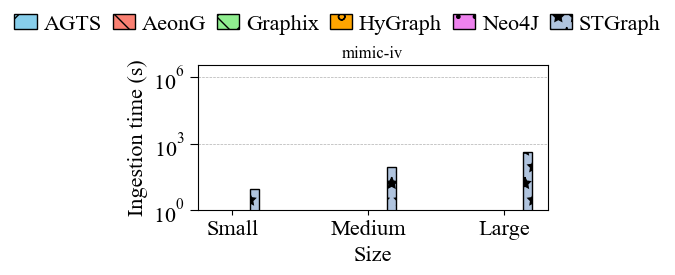

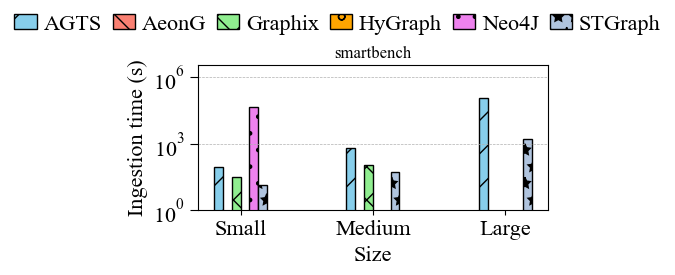

In [6]:
def print_ingestion_statistics(ingestion_statistics: pd.DataFrame):
    """
    Print ingestion statistics bar plot (log scale, clipped values, scalable patterns),
    con padding minimo sopra il limite di clipping.
    """
    import matplotlib.patches as mpatches

    df = clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine)
    
    # df = df[~((df["model"] == "Neo4J") & (df["datasetSize"] == "Medium"))]
    grouped = df.groupby(["dataset", "datasetSize", "model"], observed=True)["elapsedTime"].mean().reset_index()
    print_latex(grouped)
    all_models = sorted(grouped["model"].unique())
    all_datasets = sorted(grouped["dataset"].unique())
    num_models = len(all_models)
    bar_width = min(0.4 / num_models, 0.09)
    x = np.arange(len(dataset_order))

    for _, dataset in enumerate(all_datasets):
        fig, ax = plt.subplots(figsize=(fig_x * 1.5, fig_y))
        for i, model in enumerate(all_models):
            offset = (i - (num_models - 1) / 2) * bar_width
            for j, ds in enumerate(dataset_order):
                subset = grouped[(grouped["datasetSize"] == ds) & (grouped["model"] == model) & (grouped["dataset"] == dataset)]
                if subset.empty:
                    continue
                if model != "STGraph" and dataset == "smartbench":  # Sottrai il tempo di processing CSV solo per i modelli diversi da STGraph su SmartBench
                    # csvTime = ((df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["endTimestamp"] - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["startTimestamp"]) / 1000 - df[(df["model"] == "STGraph") & (df["datasetSize"] == ds)]["elapsedTime"]).mean()
                    csvTime = 0
                    # print(f"Average CSV processing time (s): {csvTime:.2f}")
                    #if model == "HyGraph" and dataset == "smartbench" and ds == "Medium":
                    #    value = 13.13 * 2
                    #else:
                    # print(f"STGraph elapsed time (s): {subset['elapsedTime'].values[0]:.2f}, CSV processing time (s): {csvTime:.2f}")
                    value = subset["elapsedTime"].values[0] - csvTime  # Sottrai il tempo di processing CSV
                else:
                    csvTime = 0
                    value = subset["elapsedTime"].values[0]
                # print(f"Model: {model}, Dataset: {ds}, Elapsed Time (s): {value + csvTime}, Elapsed Time - CSV (s): {value}")
                display_value = min(value, CLIP_VALUE)
                ax.bar(x[j] + offset, display_value, width=bar_width, color=colors[i % len(colors)], edgecolor='black', hatch=patterns[i % len(patterns)], label=model if j == 0 else None)
                if value >= CLIP_VALUE:
                    ax.text(x[j] + offset, CLIP_VALUE, f"X", va='center', ha='center', fontsize=font - 2, rotation=0, c="red")
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"FAIL", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
                    # ax.text(x[j] + offset, CLIP_VALUE * 1.1, f"{value:.2e}", va='bottom', ha='center', fontsize=font - 2, rotation=45, bbox=dict(facecolor='white', edgecolor='black', linewidth=0.5, alpha=0.9, pad=1.5))
        ax.set_xticks(x)
        ax.set_xticklabels(dataset_order, fontsize=font)
        ax.set_xlabel("Size", fontsize=font)
        ax.set_yscale("log")
        ax.set_ylim(1, CLIP_VALUE * 3.5)
        ax.tick_params(axis='y', which='both', length=6, labelsize=font)
        ax.yaxis.grid(True, linestyle='--', linewidth=0.5, which='major')
        ax.set_ylabel("Ingestion time (s)", fontsize=font)
        handles = [
            mpatches.Patch(facecolor=colors[i % len(colors)], hatch=patterns[i % len(patterns)], edgecolor='black', label=model)
            for i, model in enumerate(all_models)
        ]
        fig.legend(handles=handles, ncol=len(all_models), **legend_settings)
        plt.title(f"{dataset}")
        plt.tight_layout()
        plt.savefig(os.path.join(figures_path, f"ingestion_statistics_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

print_ingestion_statistics(ingestion_statistics)


In [7]:
def speed_up(df, group_cols = ["dataset", "datasetSize", "queryid"], column="model", baseline="STGraph", denominator=True):
    avg_times = (
        df.groupby(group_cols + [column], dropna=False, observed=True)["elapsedTime"]
        .mean()
        .reset_index()
        .rename(columns={"elapsedTime": "avgElapsedTime"})
    )
    def trimmed_mean(s):
        s = s.dropna().sort_values()
        if len(s) <= 2:
            return s.mean()
        boundary = 2 if len(s) > 4 else 1
        return s.iloc[boundary:-boundary].mean()   # drop min and max
    stgraph = (
        avg_times[avg_times[column] == baseline]
        [group_cols + ["avgElapsedTime"]]
        .rename(columns={"avgElapsedTime": baseline})
    )
    others = (
        avg_times[avg_times[column] != baseline]
        .rename(columns={
            column: "otherModel",
            "avgElapsedTime": "otherModelElapsedTime"
        })
    )
    result = others.merge(stgraph, on=group_cols, how="inner")
    result["speedup"] = (
        # result["otherModelElapsedTime"]
        # (result["otherModelElapsedTime"] - result["STGraph"]) / result["STGraph"]
        (result["otherModelElapsedTime"] / result[baseline]) if denominator else (result[baseline] / result["otherModelElapsedTime"])
        # result["STGraph"]
    )
    pivoted = (
        result.pivot_table(
            index=group_cols + [baseline],
            columns="otherModel",
            values="speedup", observed=True
        )
        .reset_index()
    )
    pivoted.columns.name = None
    pivoted = pivoted.groupby(["dataset", "datasetSize"], observed=True)[sorted([x for x in df[column].unique() if x != baseline])].agg(trimmed_mean).reset_index()
    return print_latex(pivoted, pivot=["dataset", "Size"], columns=None, scinotation=False)

speed_up(clean_df(ingestion_statistics.copy(deep=True), threads=1, numMachines=single_machine),  group_cols = ["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)

\begin{tabular}{llrrrrr}
\toprule
 &  & AGTS & AeonG & Graphix & HyGraph & Neo4J \\
dataset & Size &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic-iv} & S & -- & 0.0 & -- & -0.0 & -- \\
 & M & -- & 0.0 & -- & -0.0 & -- \\
 & L & -- & -0.0 & -- & -0.0 & -- \\
\cline{1-7}
\multirow[t]{3}{*}{smartbench} & S & 6.7 & 0.0 & 2.3 & -0.0 & 3447.9 \\
 & M & 11.6 & 0.0 & 2.0 & -0.0 & -0.0 \\
 & L & 70.9 & -0.0 & -- & -0.0 & -0.0 \\
\cline{1-7}
\bottomrule
\end{tabular}



In [8]:
def clean_df_stats(
    df,
    numMachines=None,
    threads=None,
    groupby_cols=None,
    queryMode=None,
    queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    queryid_exact_match=False,
    model=None
):
    # -------------------------
    # Base cleaning
    # -------------------------
    df["numMachines"] = df["numMachines"].replace(-1, 1)
    df["numMachines"] = df["numMachines"].fillna(1).astype(int)
    df = clean_df(df, threads=threads, numMachines=numMachines)
    df["queryMode"] = df["queryMode"].fillna("OPTIMIZED")
    if queryMode is not None:
        df = df[df["queryMode"] == queryMode]
    if model is not None:
        df = df[df["model"] == model]
    # -------------------------
    # Query ID normalization
    # -------------------------
    df["queryid"] = df["queryid"].fillna(df["queryName"])
    df["queryid"] = df["queryid"].apply(lambda x: str(x).replace("Neo4J", "").replace("PGAge", ""))
    df["queryid"] = df["queryid"].apply(lambda x: query_names.get(x, x))
    if queryid is not None:
        if queryid_exact_match:
            df = df[df["queryid"].isin(queryid)]
        else:
            df = df[df["queryid"].apply(lambda x: len([y for y in queryid if y in x]) > 0 )]
    # -------------------------
    # Query selectivity filter
    # -------------------------
    df["querySelectivity"] = df["querySelectivity"].fillna("increased")
    df = df[(df["querySelectivity"].isna()) | (df["querySelectivity"] == "increased")]
    # -------------------------
    # Remove specific cases
    # -------------------------
    models_to_filter = ["AeonG", "HyGraph", "Neo4J"]
    df["model"] = df["model"].apply(lambda x: x.replace("neo4j", "Neo4J").replace("stgraph", "STGraph").replace("PGAge", "AGTS"))
    df = df[~(
        df["queryName"].isin(["EnvironmentOutlier", "EnvironmentAlert"]) &
        df["model"].isin(models_to_filter)
    )]
    # -------------------------
    # Numeric safety
    # -------------------------
    df["elapsedTime"] = pd.to_numeric(df["elapsedTime"].fillna(-1), errors="coerce")
    df["cardinality"] = pd.to_numeric(df["cardinality"].fillna(-1), errors="coerce")
    # df = df.dropna(subset=["elapsedTime", "cardinality"])
    # -------------------------
    # Group + aggregate (dynamic)
    # -------------------------
    if groupby_cols is not None:
        df_grouped = (
            df
            .groupby(groupby_cols, as_index=False, observed=True)
            .agg({
                "elapsedTime": "mean",
                "cardinality": "mean"
            })
            .sort_values(groupby_cols)
        )
    else:
        df_grouped = df
    return df_grouped


In [9]:
speed_up(clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True), denominator=True)


\begin{tabular}{llrrrrrrrrrrrrrrrrrrrrrrrrrr}
\toprule
 &  & AGTS & AGTS_3CPU_12GB & AeonG & Graphix & Graphix_1CPU_NoConf & Graphix_2CPU_NoConf & Graphix_2Part & Graphix_2Part_No_index & Graphix_3CPU_12GB & Graphix_4CPU_NoConf & Graphix_Free & Graphix_opt & HyGraph & Neo4J & Neo4j_3CPU_12GB_Index & Neo4j_3CPU_12GB_NoIndex & Neo4j_3CPU_12GB_Plan & STGraph_1CPU_NoConf & STGraph_1Part_1Cpu & STGraph_2CPU_NoConf & STGraph_2Part & STGraph_4CPU_NoConf & STGraph_Free & STGraph_Free_NoParall & STGraph_onepart & STGraph_opt \\
dataset & Size &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 2.2 & -- & 5.7 & -- & -- & -- & -- & -- & -- & -- & -- & -- & 9445.5 & 2.6 & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- \\
 & M & 22.3 & -- & 35.3 & -- & -- & -- & -- & -- & -- & -- & -- & -- & 14205.1 & 1.7 & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- & -- \\
 & L & 260.0 & -- & -- & -- & -- & -- & -- & -- & --

Query statistics - <b>different</b> selectivity across dataset size

\begin{tabular}{llllllllllllllllllllllllllllll}
\toprule
 &  & Model & AGTS & AGTS_3CPU_12GB & AeonG & Graphix & Graphix_1CPU_NoConf & Graphix_2CPU_NoConf & Graphix_2Part & Graphix_2Part_No_index & Graphix_3CPU_12GB & Graphix_4CPU_NoConf & Graphix_Free & Graphix_opt & HyGraph & Neo4J & Neo4j_3CPU_12GB_Index & Neo4j_3CPU_12GB_NoIndex & Neo4j_3CPU_12GB_Plan & STGraph & STGraph_1CPU_NoConf & STGraph_1Part_1Cpu & STGraph_2CPU_NoConf & STGraph_2Part & STGraph_4CPU_NoConf & STGraph_Free & STGraph_Free_NoParall & STGraph_onepart & STGraph_opt \\
dataset & Size & ID &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & Q1 & $1.1 \cdot 10^{0}$ & -- & $2.3 \cdot 10^{0}$ & -- & -- & -- & -- & -- & -- & -- & -- & -- & $4.1 \cdot 10^{3}$ & $1.4 \cdot 10^{0}$ & -- & -- & -- & $1.3 \cdot 10^{0}$ & -- & -- & -- & -- & -- & -- & -- & -- & -- \\
 &  & Q2 & $8.7 \cdot 10^{-1}$ & -- & $2.3 \cdot 10^{0}$ & -- & -- & 

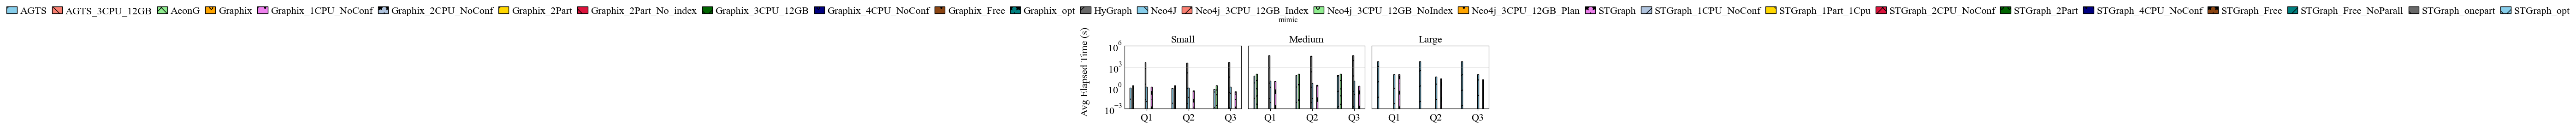

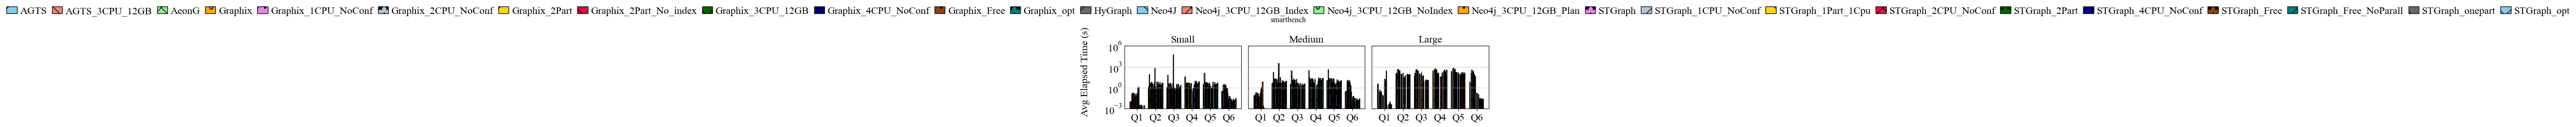

In [10]:
def print_query_statistics(query_df: pd.DataFrame):
    print_latex(query_df.dropna(subset=["elapsedTime"]).groupby(["dataset", "datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", "ID"])
    all_models = sorted(query_df["model"].unique())
    num_models = len(all_models)
    bar_width = min(0.8 / num_models, 0.18)
    for dataset in sorted(query_df["dataset"].unique()):
        fig, axes = plt.subplots(1, len(dataset_order), figsize=(fig_x * len(dataset_order), fig_y), sharey=True)
        if len(dataset_order) == 1: axes = [axes]
        for ax, ds in zip(axes, dataset_order):
            df_filtered = query_df[(query_df["dataset"] == dataset) & (query_df["datasetSize"] == ds)]
            grouped = df_filtered.groupby(["queryid", "model"], observed=True)["elapsedTime"].mean().reset_index()
            query_ids = sorted(grouped["queryid"].unique())
            x = np.arange(len(query_ids))

            for i, model in enumerate(all_models):
                values = [
                    grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ]["elapsedTime"].values[0]
                    if not grouped[
                        (grouped["queryid"] == q) &
                        (grouped["model"] == model)
                    ].empty
                    else np.nan
                    for q in query_ids
                ]

                offset = (i - (num_models - 1) / 2) * bar_width

                ax.bar(
                    x + offset,
                    values,
                    width=bar_width,
                    color=colors[i % len(colors)],
                    edgecolor="black",
                    hatch=patterns[i % len(patterns)],
                    label=model if ds == dataset_order[0] else None
                )

            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, CLIP_VALUE)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(ds, fontsize=font)

        ylabel = fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
        ylabel.set_position((-0.00005, 0.5))  # sposta più vicino ai tick senza sovrapporsi
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(all_models), **legend_settings)
        plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_statistics_{dataset}.svg"), bbox_inches='tight')
        plt.show()

query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7"], queryid_exact_match=True)
print_query_statistics(query_df)

In [11]:
graphix_df = query_df.loc[(query_df["model"].str.contains("Graph")) & (query_df["dataset"] == "smartbench") & (query_df["model"] != "HyGraph")]
graphix_df

,test_id,queryid,model,dataset,datasetSize,threads,elapsedTime,numMachines,cardinality,queryMode,sortBy,queryName,queryType,numEntities,querySelectivity,temporalRangeIndex,iteration
80,471fa8ee-86de-441a-adff-7074306b7f98,Q6,STGraph,smartbench,Extralarge,1,0.047,1,1.0,OPTIMIZED,AgentHistory extralarge,NaN,NaN,NaN,increased,NaN,NaN
81,056a9ad9-2ee2-4df4-a74f-0d1dae0b4b48,Q6,STGraph,smartbench,Extralarge,1,0.046,1,1.0,OPTIMIZED,AgentHistory extralarge,NaN,NaN,NaN,increased,NaN,NaN
91,6317c7d2-ebd2-44c2-b4a4-b7c8c555b456,Q6,STGraph,smartbench,Extralarge,1,0.041,1,1.0,OPTIMIZED,AgentHistory extralarge,NaN,NaN,NaN,increased,NaN,NaN
92,b4e4648a-5c31-4f57-a22e-7cf131701b93,Q6,STGraph,smartbench,Extralarge,1,0.041,1,1.0,OPTIMIZED,AgentHistory extralarge,NaN,NaN,NaN,increased,NaN,NaN
101,3756d7cb-99ae-4e63-8b57-85ed52f5200e,Q6,STGraph,smartbench,Large,1,0.039,1,1.0,OPTIMIZED,AgentHistory large,NaN,NaN,NaN,increased,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12053,f1d6921b-72c3-446c-96be-cd6e97924231,Q2,Graphix_3CPU_12GB,smartbench,Medium,1,13.291,1,95.0,OPTIMIZED,9 increased 0,NaN,NaN,NaN,increased,NaN,NaN
12054,44e38db5-184c-4f33-9ea0-faf4dda7dd33,Q3,Graphix_3CPU_12GB,smartbench,Medium,1,13.484,1,200.0,OPTIMIZED,9 increased 0,NaN,NaN,NaN,increased,NaN,NaN
12055,5397315a-b42f-486d-a868-b7fbf1dbe483,Q4,Graphix_3CPU_12GB,smartbench,Medium,1,15.788,1,3.0,OPTIMIZED,9 increased 0,NaN,NaN,NaN,increased,NaN,NaN
12056,ca6ba82b-9daf-48e9-8d24-bbc3c1d14a04,Q5,Graphix_3CPU_12GB,smartbench,Medium,1,16.571,1,200.0,OPTIMIZED,9 increased 0,NaN,NaN,NaN,increased,NaN,NaN


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & queryMode &  &  &  &  &  &  \\
\midrule
\multirow[t]{5}{*}{mimic} & \multirow[t]{2}{*}{S} & NAIVE & $6.8 \cdot 10^{0}$ & $7.1 \cdot 10^{0}$ & $7.2 \cdot 10^{0}$ & -- & -- & -- \\
 &  & OPTIMIZED & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{2}{*}{M} & NAIVE & $4.7 \cdot 10^{1}$ & $4.6 \cdot 10^{1}$ & $3.9 \cdot 10^{1}$ & -- & -- & -- \\
 &  & OPTIMIZED & $7.9 \cdot 10^{0}$ & $2.6 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & -- & -- & -- \\
\cline{2-9}
 & L & OPTIMIZED & $7.9 \cdot 10^{1}$ & $2.2 \cdot 10^{1}$ & $1.5 \cdot 10^{1}$ & -- & -- & -- \\
\cline{1-9} \cline{2-9}
\multirow[t]{8}{*}{smartbench} & \multirow[t]{2}{*}{--} & NAIVE & $3.5 \cdot 10^{-3}$ & -- & -- & -- & -- & $3.7 \cdot 10^{1}$ \\
 &  & OPTIMIZED & $3.5 \cdot 10^{-3}$ & $1.6 \cdot 10^{2}$ & $1.3 \cdot 10^{1}$ & $9.5 \cdot 10^{2}$ & $1.4 \cdot 10^{2}$ & $4.4 \cdot 10^{-

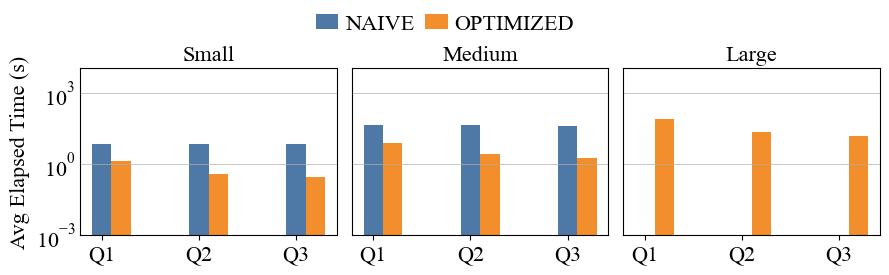

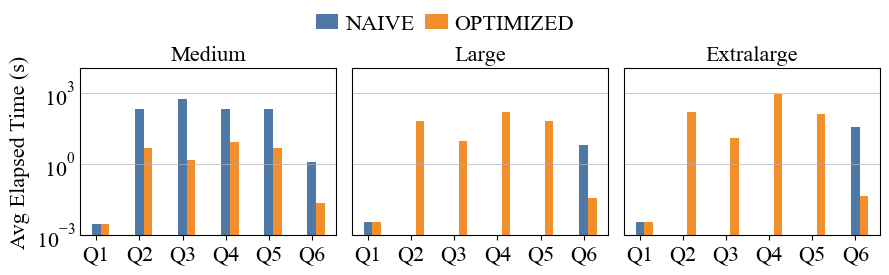

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


def plot_per_dataset(df_grouped, column="queryMode", title="opt", onlylast=False):
    datasets = df_grouped["dataset"].unique()
    print_latex(df_grouped.dropna().groupby(["dataset", "datasetSize", "queryid", column], observed=True)["elapsedTime"].mean().reset_index(), pivot=["dataset", "Size", column], columns="ID")
    for dataset in datasets:
        df_d = df_grouped[df_grouped["dataset"] == dataset]
        sizes = ["Small", "Medium", "Large", "Extralarge"]
        if title == "opt" and dataset == "smartbench":
            sizes = ["Medium", "Large", "Extralarge"]
        sizes = [s for s in sizes if s in df_d["datasetSize"].unique()]
        if onlylast:
            sizes = [sizes[-1]]
        query_ids = sorted(df_d["queryid"].unique())
        query_modes = sorted(df_d[column].unique())

        if onlylast:
            nrows, ncols = 1, 1
        else:
            nrows = 2 if len(sizes) > 3 else 1
            ncols = 3

        fig, axes = plt.subplots(
            nrows,
            ncols,
            figsize=(fig_x * ncols, fig_y * nrows),
            sharey=True
        )

        axes = np.atleast_1d(axes).flatten()

        for i in range(len(sizes), len(axes)):
            axes[i].set_visible(False)

        axes = axes[:len(sizes)]

        j = 0
        for ax, size in zip(axes, sizes):
            df_s = df_d[df_d["datasetSize"] == size]

            # pivot: rows=queryid, cols=queryMode
            pivot = df_s.pivot(
                index="queryid",
                columns=column,
                values="elapsedTime"
            ).reindex(query_ids)

            x = np.arange(len(query_ids))
            width = 0.2 # 0.8 / len(query_modes)

            for i, mode in enumerate(query_modes):
                values = pivot[mode] if mode in pivot else [0]*len(query_ids)

                bars = ax.bar(
                    x + i * width,
                    values,
                    width=width,
                    label=mode
                )
            ax.set_title(f"Size: {size}")
            ax.set_xticks(x + width * (len(query_modes) - 1) / 2)
            # --- X axis ---
            ax.set_xticks(x)
            ax.set_xticklabels(query_ids, fontsize=font)  # tick X più grandi

            # --- Y axis ---
            ax.set_yscale("log")
            ax.set_ylim(0.001, 11000)
            ax.tick_params(axis="y", which="major", labelsize=font)
            ax.tick_params(axis="y", which="both", length=0)
            ax.yaxis.grid(True, which='major', linestyle='-', linewidth=0.5)
            ax.set_title(size, fontsize=font)
            if (j % 3 == 0):
                ax.set_ylabel("Avg Elapsed Time (s)", fontsize=font)
            j += 1


        # shared legend
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, ncol=len(query_modes), **legend_settings)
        # plt.suptitle(f"{dataset}")
        plt.tight_layout()  # margini ottimizzati
        plt.savefig(os.path.join(figures_path, f"query_{title}_{dataset}.pdf"), bbox_inches='tight')
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, title="opt", onlylast=False)

/tmp/ipykernel_56616/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & threads &  &  &  &  &  &  \\
\midrule
\multirow[t]{12}{*}{mimic} & \multirow[t]{4}{*}{S} & 1 & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $4.1 \cdot 10^{-1}$ & $1.2 \cdot 10^{-1}$ & $9.3 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 8 & $4.0 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & $5.4 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 16 & $3.9 \cdot 10^{-1}$ & $9.7 \cdot 10^{-2}$ & $5.0 \cdot 10^{-2}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{M} & 1 & $7.9 \cdot 10^{0}$ & $2.6 \cdot 10^{0}$ & $1.8 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $2.1 \cdot 10^{0}$ & $7.0 \cdot 10^{-1}$ & $4.7 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 8 & $1.4 \cdot 10^{0}$ & $4.8 \cdot 10^{-1}$ & $3.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 16 & $1.2 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{4}{*}{L} & 1 & $7.9 \cdot 10

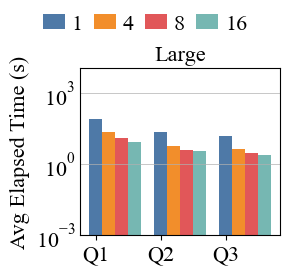

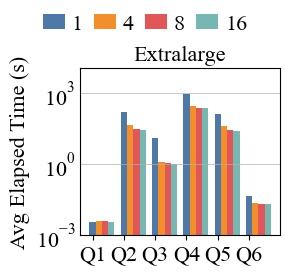

In [13]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "threads"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="threads", title="threads", onlylast=True)

In [14]:
speed_up(df_grouped, column="threads", baseline=1, denominator=False)

\begin{tabular}{llrrr}
\toprule
 &  & 4 & 8 & 16 \\
dataset & Size &  &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 3.2 & 3.8 & 4.1 \\
 & M & 3.7 & 5.5 & 6.5 \\
 & L & 3.6 & 5.6 & 6.5 \\
\cline{1-5}
\multirow[t]{4}{*}{smartbench} & S & 3.4 & 4.9 & 5.4 \\
 & M & 3.2 & 4.4 & 4.9 \\
 & L & 2.9 & 3.9 & 4.3 \\
 & -- & 3.3 & 4.5 & 4.9 \\
\cline{1-5}
\bottomrule
\end{tabular}



\begin{tabular}{lllllllll}
\toprule
 &  & ID & Q1 & Q2 & Q3 & Q4 & Q5 & Q6 \\
dataset & Size & numMachines &  &  &  &  &  &  \\
\midrule
\multirow[t]{9}{*}{mimic} & \multirow[t]{3}{*}{S} & 1 & $3.9 \cdot 10^{-1}$ & $9.7 \cdot 10^{-2}$ & $5.0 \cdot 10^{-2}$ & -- & -- & -- \\
 &  & 2 & $6.1 \cdot 10^{-1}$ & $3.3 \cdot 10^{-1}$ & $1.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $4.2 \cdot 10^{-1}$ & $8.5 \cdot 10^{-2}$ & $6.9 \cdot 10^{-2}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{M} & 1 & $1.2 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $3.0 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 2 & $1.3 \cdot 10^{0}$ & $4.0 \cdot 10^{-1}$ & $2.2 \cdot 10^{-1}$ & -- & -- & -- \\
 &  & 4 & $1.1 \cdot 10^{0}$ & $3.0 \cdot 10^{-1}$ & $2.5 \cdot 10^{-1}$ & -- & -- & -- \\
\cline{2-9}
 & \multirow[t]{3}{*}{L} & 1 & $8.8 \cdot 10^{0}$ & $3.5 \cdot 10^{0}$ & $2.4 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 2 & $1.0 \cdot 10^{1}$ & $2.4 \cdot 10^{0}$ & $1.7 \cdot 10^{0}$ & -- & -- & -- \\
 &  & 4 & $9.7 \cdot 10^

/tmp/ipykernel_56616/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


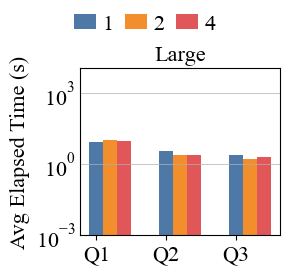

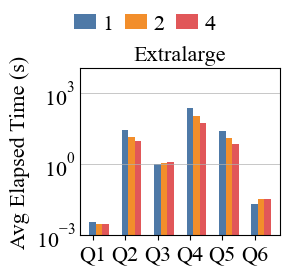

In [15]:
df_grouped = clean_df_stats(query_statistics.copy(deep=True), queryMode="OPTIMIZED", threads=16, groupby_cols=["dataset", "datasetSize", "queryid", "numMachines"], queryid_exact_match=True, model="STGraph")
plot_per_dataset(df_grouped, column="numMachines", title="numMachines", onlylast=True)

In [16]:
speed_up(df_grouped, column="numMachines", baseline=1, denominator=False)

\begin{tabular}{llrr}
\toprule
 &  & 2 & 4 \\
dataset & Size &  &  \\
\midrule
\multirow[t]{3}{*}{mimic} & S & 0.5 & 0.9 \\
 & M & 1.0 & 1.2 \\
 & L & 1.4 & 1.2 \\
\cline{1-4}
\multirow[t]{4}{*}{smartbench} & S & 0.9 & 0.9 \\
 & M & 1.1 & 1.0 \\
 & L & 1.1 & 1.2 \\
 & -- & 1.5 & 2.0 \\
\cline{1-4}
\bottomrule
\end{tabular}



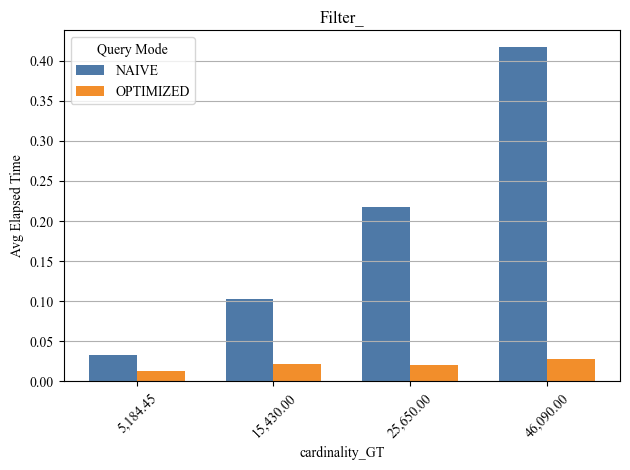

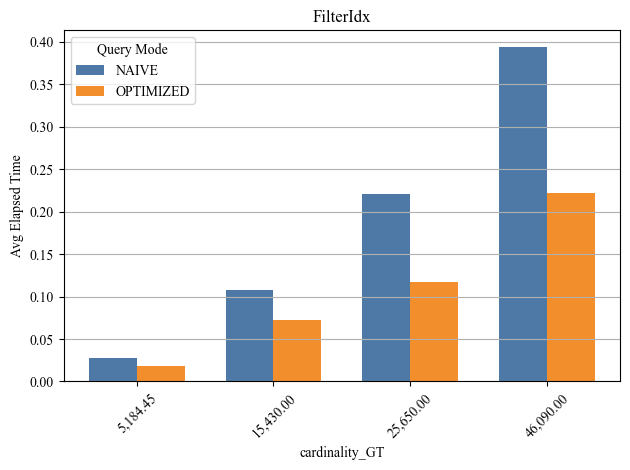

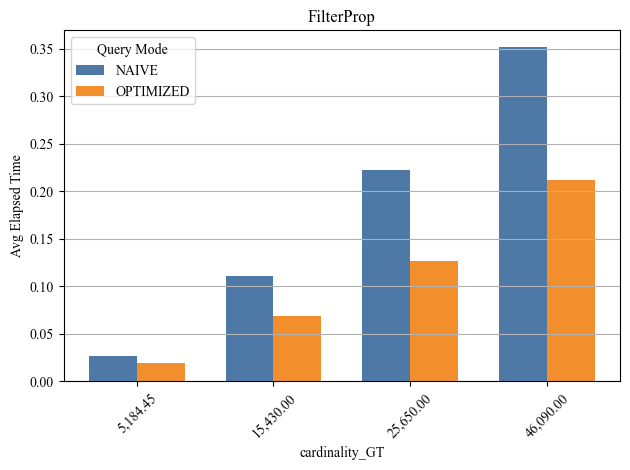

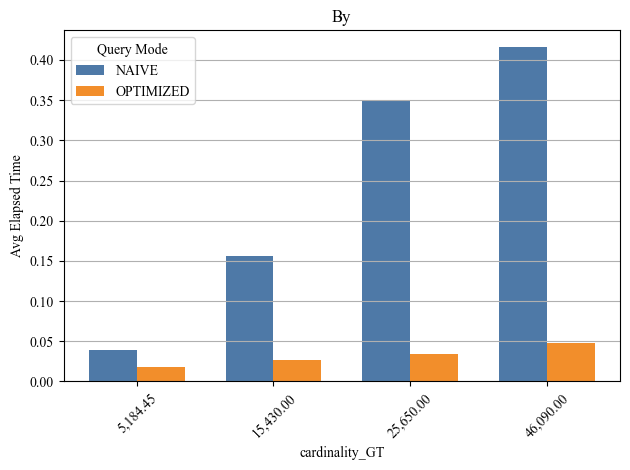

In [17]:
def plot_s(df_grouped, filter):
    for col in ["cardinality_GT"]: # , "cardinality_ratio", "cardinality"
        # --- parameters ---
        num_bins = 5

        df_grouped["card_bin"] = pd.cut(df_grouped[col], bins=num_bins)

        # df_grouped["card_bin"] = df_grouped[col]

        # aggregate
        agg = (
            df_grouped.groupby(["queryMode", "card_bin"], observed=True)
            .agg({
                "elapsedTime": "mean"
            })
            .reset_index()
        )

        # pivot → rows = bins, columns = queryModes
        pivot = agg.pivot(index="card_bin", columns="queryMode", values="elapsedTime")

        # use bin centers for labels (cleaner than intervals)
        bin_centers = [interval.mid for interval in pivot.index]

        # --- plotting ---
        x = np.arange(len(pivot))  # bin positions
        width = 0.35               # bar width

        plt.figure()

        for i, mode in enumerate(pivot.columns):
            plt.bar(
                x + i * width,
                pivot[mode],
                width=width,
                label=mode
            )

        plt.xticks(x + width * (len(pivot.columns) - 1) / 2, [f"{c:,.2f}" for c in bin_centers], rotation=45)
        plt.xlabel(col)
        plt.ylabel("Avg Elapsed Time")
        plt.title(filter)
        plt.legend(title="Query Mode")
        plt.grid(axis="y")

        plt.tight_layout()
        plt.show()

df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=["Filter_", "FilterIdx", "FilterProp", "By"])
df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
df_grouped["queryType"] = df_grouped["queryid"].apply(lambda x: x.split("_")[0])
df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
df_grouped.to_csv(os.path.join(statistics_path, "query_statistics_filtered.csv"), index=False)

for filter in ["Filter_", "FilterIdx", "FilterProp", "By"]:
    df_grouped = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, groupby_cols=["dataset", "datasetSize", "queryid", "queryMode"], queryid=[filter])
    df_grouped["cardinality_GT"] = df_grouped["queryid"].apply(lambda x: x.split("_")[2]).astype(int)
    df_grouped["cardinality_ratio"] = df_grouped["cardinality"] / df_grouped["cardinality_GT"]
    plot_s(df_grouped, filter)

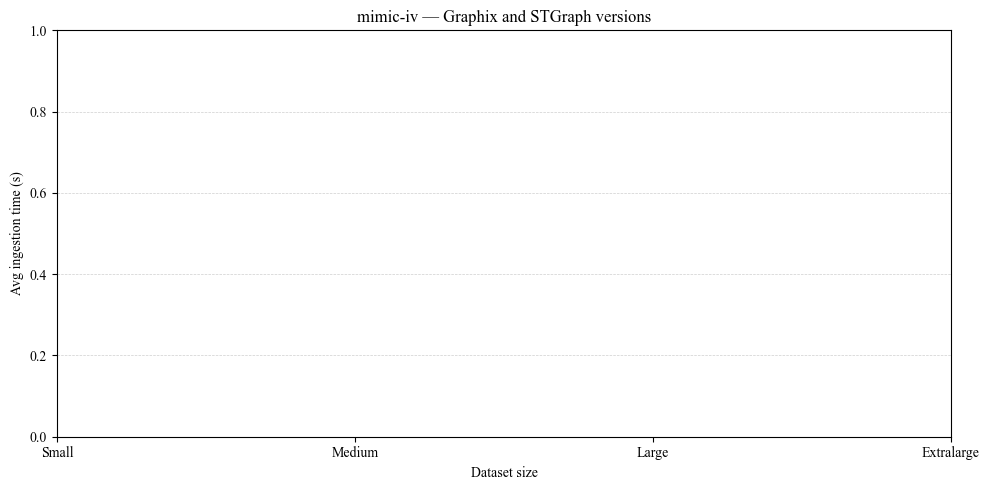

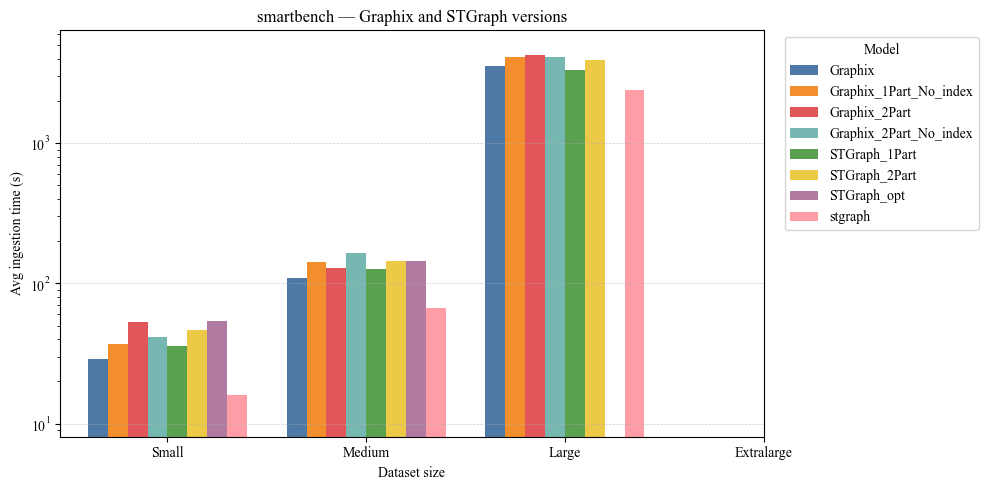

In [18]:
graphix_ingestion_versions = [
    "Graphix",
    "Graphix_2Part",
    "Graphix_2Part_No_index",
    "Graphix_1Part_No_index",
]
stgraph_ingestion_versions = [
    "STGraph",
    "STGraph_1Part",
    "STGraph_2Part",
    "STGraph_opt",
    "stgraph",
]

ingestion_compare = (
    ingestion_statistics[
        ingestion_statistics["model"].isin(graphix_ingestion_versions + stgraph_ingestion_versions)
    ].copy()
)
ingestion_compare["datasetSize"] = ingestion_compare["datasetSize"].astype(str)
if "tsElapsedTime" in ingestion_compare.columns:
    ingestion_compare["elapsedTime"] = pd.to_numeric(ingestion_compare["tsElapsedTime"], errors="coerce") / 1000
else:
    ingestion_compare["elapsedTime"] = pd.to_numeric(ingestion_compare["elapsedTime"], errors="coerce") / 1000

ingestion_summary = (
    ingestion_compare
    .groupby(["dataset", "datasetSize", "model"], as_index=False, observed=True)
    .agg(avg_ingestion_time_s=("elapsedTime", "mean"))
    .sort_values(["dataset", "datasetSize", "avg_ingestion_time_s"])
)

size_order = ["Small", "Medium", "Large", "Extralarge"]

for dataset in sorted(ingestion_summary["dataset"].unique()):
    subset = ingestion_summary[ingestion_summary["dataset"] == dataset].copy()
    subset["datasetSize"] = pd.Categorical(
        subset["datasetSize"],
        categories=size_order,
        ordered=True,
    )
    subset = subset.sort_values(["datasetSize", "model"])

    models = sorted(subset["model"].unique())
    x = np.arange(len(size_order))
    bar_width = 0.8 / max(len(models), 1)

    fig, ax = plt.subplots(figsize=(10, 5))
    all_positive = []
    for i, model in enumerate(models):
        model_data = subset[subset["model"] == model].sort_values("datasetSize")
        y = [
            float(model_data[model_data["datasetSize"] == size]["avg_ingestion_time_s"].mean())
            if size in model_data["datasetSize"].astype(str).values
            else np.nan
            for size in size_order
        ]
        positive = [val for val in y if np.isfinite(val) and val > 0]
        if not positive:
            continue
        all_positive.extend(positive)
        ax.bar(
            x + (i - (len(models) - 1) / 2) * bar_width,
            y,
            width=bar_width,
            label=model,
        )

    ax.set_title(f"{dataset} — Graphix and STGraph versions")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Avg ingestion time (s)")
    ax.set_xticks(x)
    ax.set_xticklabels(size_order)
    if all_positive:
        ax.set_yscale("log")
        ax.set_ylim(min(all_positive) * 0.5, max(all_positive) * 1.5)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.6)
    if ax.containers:
        ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


## Configurazioni dei cluster

Le varianti di STGraph e Graphix contro STGraph del paper (model `stgraph`, che `clean_df` chiama `STGraph`), con i filtri del paper (smartbench, OPTIMIZED, 1 thread, 1 macchina) e lo speedup di `speed_up`: tempo della variante / tempo di STGraph, per le query la media troncata sulle sei query, per l'ingestion il tempo degli eventi (`tsElapsedTime`). Sopra 1 la variante è più lenta del paper.

`STGraph_1Part` (ingestion) è letto come `stgraph_onepart` (query), e `Graphix` è accoppiato a `stgraph_onepart`: stessa configurazione, nomi diversi nei file.

AGTS come Neo4j: l'AGTS del paper come riferimento e le sue configurazioni (`AGTS_*`, nei file `PGAge_*`), solo query.

In [19]:
# Le configurazioni: tutte le varianti nei dati, riconosciute dal nome (STGraph_*, Graphix*, Neo4j_* e il Neo4J del
# paper, AGTS_* e l'AGTS del paper); nei grafici tutte tranne quelle di hidden_configurations (cella sotto), nelle tabelle tutte
# Il numero dei risultati: cardinality (STGraph, Graphix), numEntities (Neo4j, AGTS)
configurations_query_statistics = query_statistics.copy(deep=True)
configurations_query_statistics["cardinality"] = configurations_query_statistics["cardinality"].fillna(configurations_query_statistics["numEntities"])
configurations_query_df = clean_df_stats(configurations_query_statistics, numMachines=1, queryMode="OPTIMIZED", queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
configurations_query_df = configurations_query_df[
    (configurations_query_df["dataset"] == "smartbench") & configurations_query_df["datasetSize"].isin(dataset_order)
].copy()

configurations_ingestion_df = clean_df(ingestion_statistics.copy(deep=True), threads=1)
configurations_ingestion_df["model"] = configurations_ingestion_df["model"].replace({"STGraph_1Part": "STGraph_onepart"})
configurations_ingestion_df = configurations_ingestion_df[
    (configurations_ingestion_df["dataset"] == "smartbench") & configurations_ingestion_df["datasetSize"].isin(dataset_order)
].copy()

models = set(configurations_query_df["model"]) | set(configurations_ingestion_df["model"])
stgraph_configurations = sorted(m for m in models if m.startswith("STGraph_"))
graphix_configurations = sorted(m for m in models if m.startswith("Graphix"))
# Neo4J è il Neo4j del paper (riferimento), le altre sono le sue configurazioni
neo4j_configurations = ["Neo4J"] + sorted(m for m in models if m.startswith("Neo4j_"))
# AGTS è il PGAge del paper (riferimento), le altre (PGAge_* nei file) sono le sue configurazioni
agts_configurations = ["AGTS"] + sorted(m for m in models if m.startswith("AGTS_"))
configurations = stgraph_configurations + graphix_configurations + neo4j_configurations + agts_configurations

# Nei grafici e nelle tabelle tutte le configurazioni tranne queste (il controllo delle cardinalità in fondo le
# considera tutte)
hidden_configurations = [
    "STGraph_2Part", "STGraph_opt", "STGraph_1CPU_NoConf", "STGraph_2CPU_NoConf", "STGraph_4CPU_NoConf",
    "STGraph_Free_NoParall", "STGraph_1Part_1Cpu", "STGraph_1Part_1Cpu_Conf",
    "Graphix", "Graphix_2Part", "Graphix_opt", "Graphix_1CPU_NoConf", "Graphix_2CPU_NoConf", "Graphix_4CPU_NoConf",
    "Graphix_2Part_No_index", "Neo4j_3CPU_12GB_Plan"
]

# STGraph del paper con un thread; ogni configurazione con i suoi thread (es. 2 per STGraph_3CPU_2Threads)
configurations_query_df = configurations_query_df[
    (((configurations_query_df["model"] == "STGraph") & (configurations_query_df["threads"] == 1))
       | configurations_query_df["model"].isin(configurations))
    # Come nel paper, senza EnvironmentOutlier (Q4) di Neo4j: la sua query ha un'altra soglia
    & ~(configurations_query_df["model"].isin(neo4j_configurations) & (configurations_query_df["queryid"] == "Q4"))
].copy()
speed_up(configurations_query_df[~configurations_query_df["model"].isin(hidden_configurations)], denominator=True)

# STGraph del paper: la sua ingestion con numMachines -1, come nella tabella del paper. Neo4j e AGTS: solo query (la loro
# ingestion del paper è calcolata a parte, nella tabella del paper)
configurations_ingestion_df = configurations_ingestion_df[
    ((configurations_ingestion_df["model"] == "STGraph") & (configurations_ingestion_df["numMachines"] == -1))
    | configurations_ingestion_df["model"].isin(stgraph_configurations + graphix_configurations)
].copy()
speed_up(configurations_ingestion_df[~configurations_ingestion_df["model"].isin(hidden_configurations)], group_cols=["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)

\begin{tabular}{llrrrrrrrrrrr}
\toprule
 &  & AGTS & AGTS_3CPU_12GB & Graphix_3CPU_12GB & Graphix_Free & Neo4J & Neo4j_3CPU_12GB_Index & Neo4j_3CPU_12GB_NoIndex & STGraph_3CPU_2Threads & STGraph_3CPU_3Threads & STGraph_Free & STGraph_onepart \\
dataset & Size &  &  &  &  &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 4.3 & 1.9 & 3.2 & 1.2 & 1.8 & 0.6 & 3.7 & 1.2 & 1.2 & 1.2 & 2.3 \\
 & M & 7.7 & 3.1 & 6.2 & 1.7 & 2.1 & 0.9 & 2.5 & 1.0 & 0.9 & 1.2 & 2.0 \\
 & L & 4.8 & 13.5 & -- & 5.6 & 4.8 & 4.4 & -- & 1.0 & 0.7 & 1.2 & 1.4 \\
\cline{1-13}
\bottomrule
\end{tabular}

\begin{tabular}{llrrrr}
\toprule
 &  & Graphix_1Part_No_index & Graphix_Free & STGraph_Free & STGraph_onepart \\
dataset & Size &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.9 & 0.5 & 0.7 & 2.8 \\
 & M & 2.7 & 0.6 & 0.6 & 2.4 \\
 & L & 2.5 & 0.7 & -- & 2.0 \\
\cline{1-6}
\bottomrule
\end{tabular}



/tmp/ipykernel_56616/2614226497.py:72: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["elapsedTime"] = pd.to_numeric(df["elapsedTime"], errors="coerce") / 1000


datasetSize,Small,Medium,Large
model,,,
AGTS,4.34,7.68,4.84
AGTS_3CPU_12GB,1.92,3.10,13.54
Graphix_3CPU_12GB,3.22,6.21,NaN
Graphix_Free,1.19,1.72,5.63
Neo4J,1.76,2.09,4.79
Neo4j_3CPU_12GB_Index,0.57,0.89,4.35
Neo4j_3CPU_12GB_NoIndex,3.68,2.50,NaN
STGraph_3CPU_2Threads,1.21,1.01,0.99
STGraph_3CPU_3Threads,1.16,0.95,0.74


datasetSize,Small,Medium,Large
model,,,
Graphix_1Part_No_index,2.95,2.69,2.47
Graphix_Free,0.53,0.56,0.66
STGraph_Free,0.69,0.62,NaN
STGraph_onepart,2.82,2.37,2.01


Query, STGraph: nei grafici ['STGraph_3CPU_2Threads', 'STGraph_3CPU_3Threads', 'STGraph_Free', 'STGraph_onepart']; nascoste ['STGraph_1CPU_NoConf', 'STGraph_1Part_1Cpu', 'STGraph_2CPU_NoConf', 'STGraph_2Part', 'STGraph_4CPU_NoConf', 'STGraph_Free_NoParall', 'STGraph_opt']
Query, Graphix: nei grafici ['Graphix_3CPU_12GB', 'Graphix_Free']; nascoste ['Graphix', 'Graphix_1CPU_NoConf', 'Graphix_2CPU_NoConf', 'Graphix_2Part', 'Graphix_2Part_No_index', 'Graphix_4CPU_NoConf', 'Graphix_opt']
Query, Neo4j: nei grafici ['Neo4J', 'Neo4j_3CPU_12GB_Index', 'Neo4j_3CPU_12GB_NoIndex']; nascoste ['Neo4j_3CPU_12GB_Plan']
Query, AGTS: nei grafici ['AGTS', 'AGTS_3CPU_12GB']; nascoste []


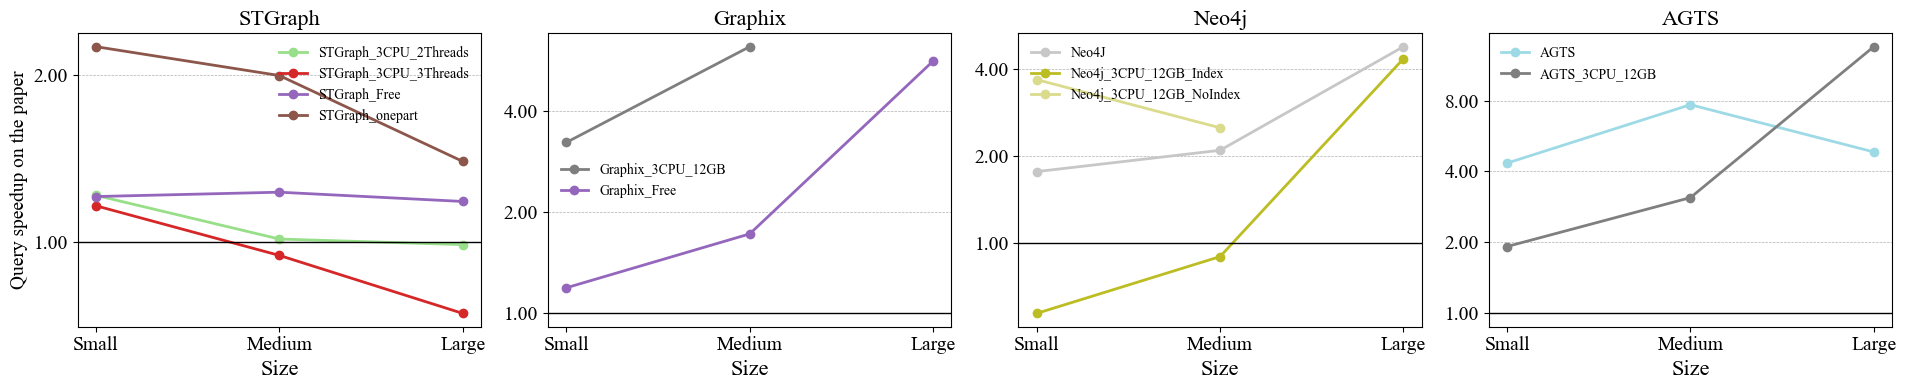

Ingestion, STGraph: nei grafici ['STGraph_Free', 'STGraph_onepart']; nascoste ['STGraph_1CPU_NoConf', 'STGraph_1Part_1Cpu_Conf', 'STGraph_2CPU_NoConf', 'STGraph_2Part', 'STGraph_4CPU_NoConf', 'STGraph_opt']
Ingestion, Graphix: nei grafici ['Graphix_1Part_No_index', 'Graphix_Free']; nascoste ['Graphix', 'Graphix_1CPU_NoConf', 'Graphix_2CPU_NoConf', 'Graphix_2Part', 'Graphix_2Part_No_index', 'Graphix_4CPU_NoConf']
Ingestion, Neo4j: nei grafici []; nascoste []
Ingestion, AGTS: nei grafici []; nascoste []


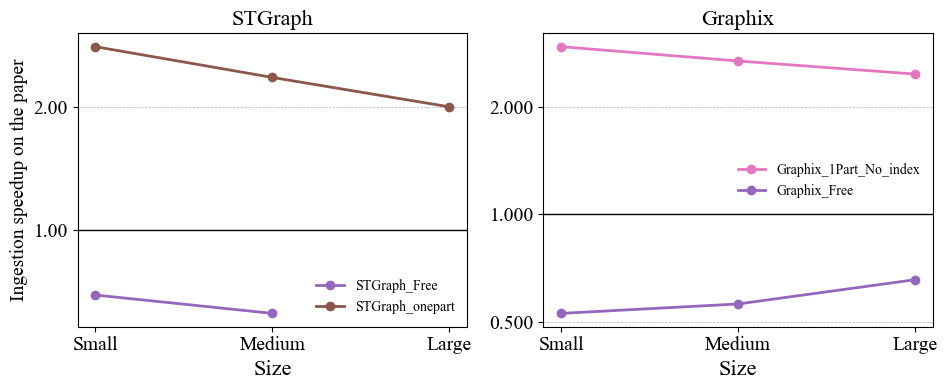

In [20]:
def trimmed_mean(s):
    # Come in speed_up: senza le due più basse e le due più alte (una sola se sono al più quattro)
    s = s.dropna().sort_values()
    if len(s) <= 2:
        return s.mean()
    boundary = 2 if len(s) > 4 else 1
    return s.iloc[boundary:-boundary].mean()

def speed_up_by_size(df, group_cols, baseline="STGraph", agg="mean"):
    """Gli speedup di speed_up come DataFrame: una riga per dimensione, una colonna per variante; agg: la media delle
    iterazioni (come speed_up) o la mediana"""
    avg = df.groupby(group_cols + ["model"], observed=True)["elapsedTime"].agg(agg).unstack("model")
    ratio = avg.drop(columns=baseline).div(avg[baseline], axis=0)
    result = ratio.groupby(level="datasetSize", observed=True).agg(trimmed_mean)
    result.index = result.index.astype(str)
    return result.reindex(dataset_order)

def configuration(model):
    """La configurazione del cluster di una variante, senza il sistema (Graphix è quella di STGraph_onepart)"""
    return model.split("_", 1)[1] if "_" in model else ("onepart" if model == "Graphix" else model)

# Stesso colore per la stessa configurazione nei sistemi (20 colori: le configurazioni sono più di 10)
configuration_palette = plt.get_cmap("tab20").colors
configuration_names = list(dict.fromkeys(configuration(m) for m in configurations))
configuration_colors = {m: configuration_palette[configuration_names.index(configuration(m)) % len(configuration_palette)]
                        for m in configurations}

query_speedup = speed_up_by_size(configurations_query_df, ["datasetSize", "queryid"])
ingestion_speedup = speed_up_by_size(configurations_ingestion_df, ["datasetSize"])
display(query_speedup.drop(columns=hidden_configurations, errors="ignore").T.round(2))
display(ingestion_speedup.drop(columns=hidden_configurations, errors="ignore").T.round(2))

for name, speedup in [("Query", query_speedup), ("Ingestion", ingestion_speedup)]:
    # Un pannello per sistema con almeno una variante da graficare (Neo4j e AGTS: solo query)
    panels = []
    for system, models in [("STGraph", stgraph_configurations), ("Graphix", graphix_configurations), ("Neo4j", neo4j_configurations), ("AGTS", agts_configurations)]:
        present = [m for m in models if m in speedup.columns and speedup[m].notna().any()]
        shown = [m for m in present if m not in hidden_configurations]
        print(f"{name}, {system}: nei grafici {shown}; nascoste {[m for m in present if m in hidden_configurations]}")
        if shown:
            panels.append((system, shown))
    fig, axes = plt.subplots(1, len(panels), figsize=(fig_x * 1.6 * len(panels), fig_y * 1.6), squeeze=False)
    for ax, (system, shown) in zip(axes[0], panels):
        for model in shown:
            ax.plot(dataset_order, speedup[model].values, marker="o", linewidth=2, color=configuration_colors[model], label=model)
        ax.axhline(1, color="black", linewidth=1)  # STGraph del paper
        ax.set_yscale("log", base=2)
        ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
        ax.set_title(system, fontsize=font)
        ax.set_xlabel("Size", fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
        ax.legend(fontsize=font - 6, frameon=False)
    axes[0][0].set_ylabel(f"{name} speedup on the paper", fontsize=font - 2)
    plt.tight_layout()
    plt.show()

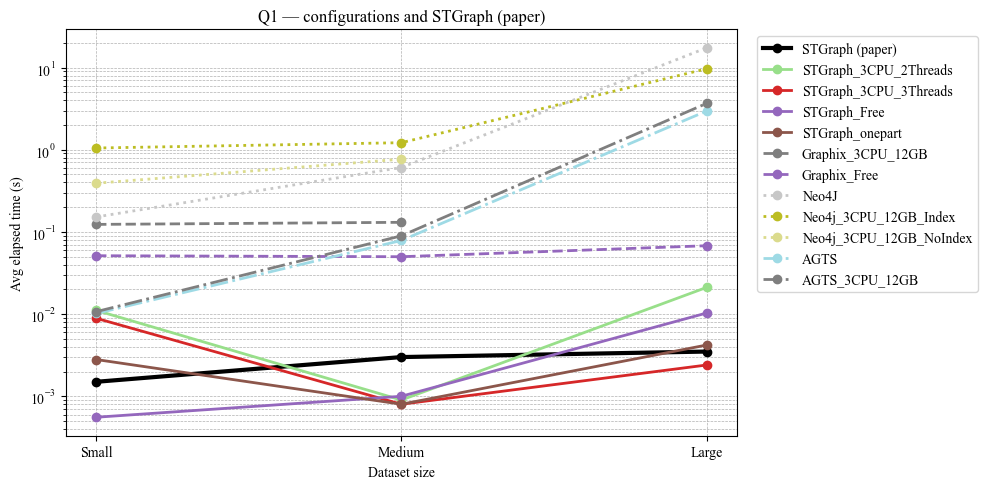

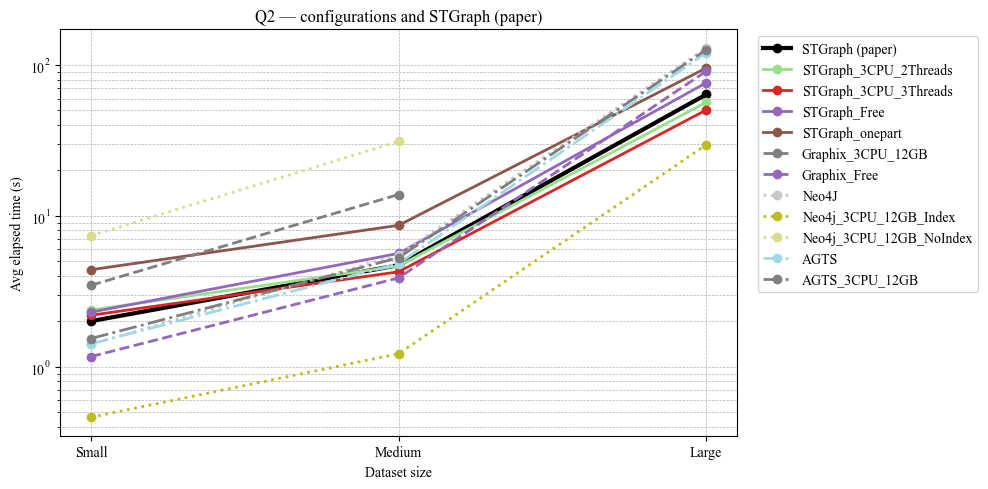

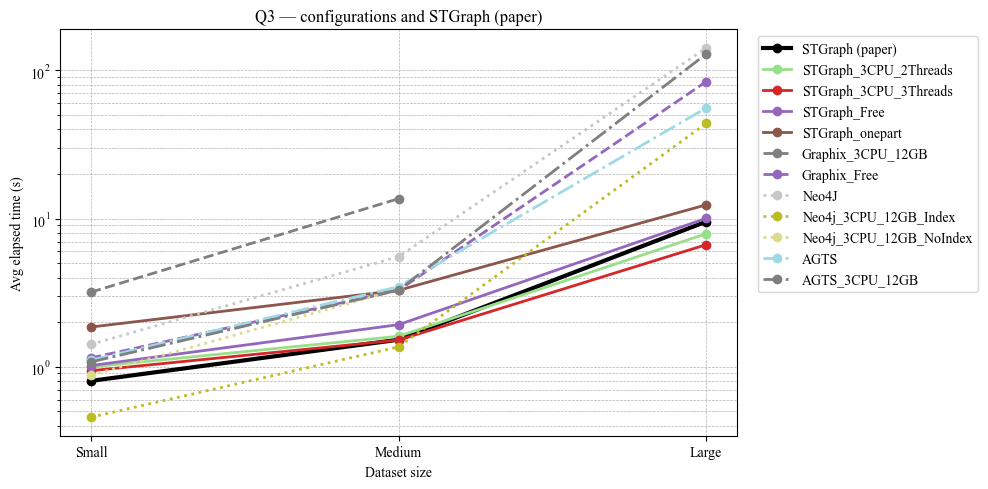

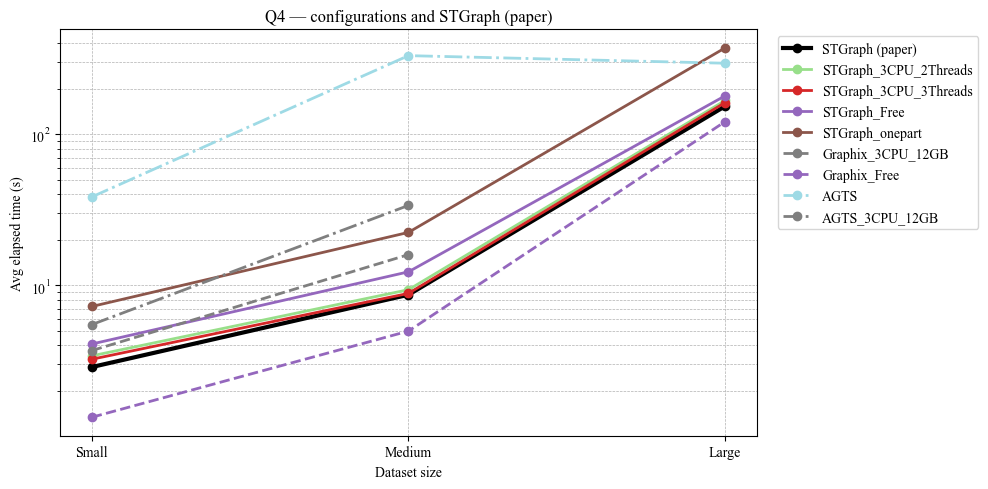

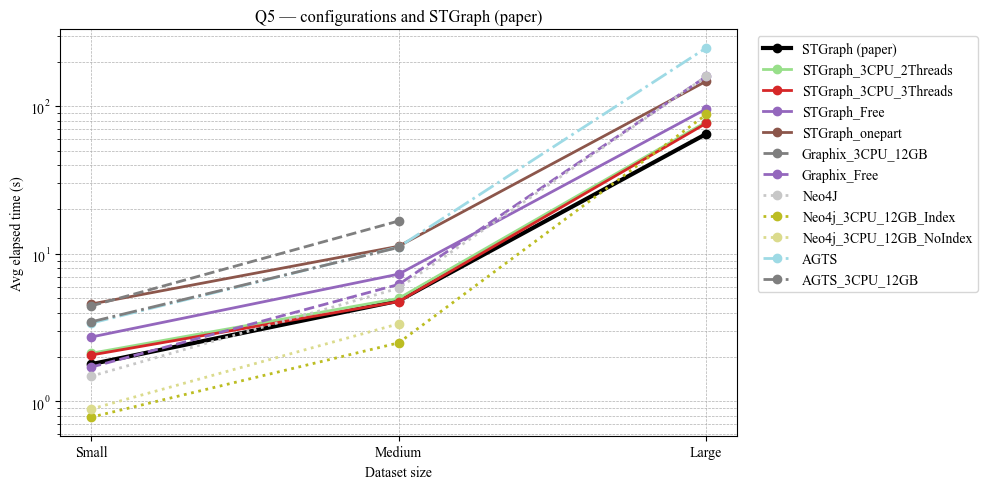

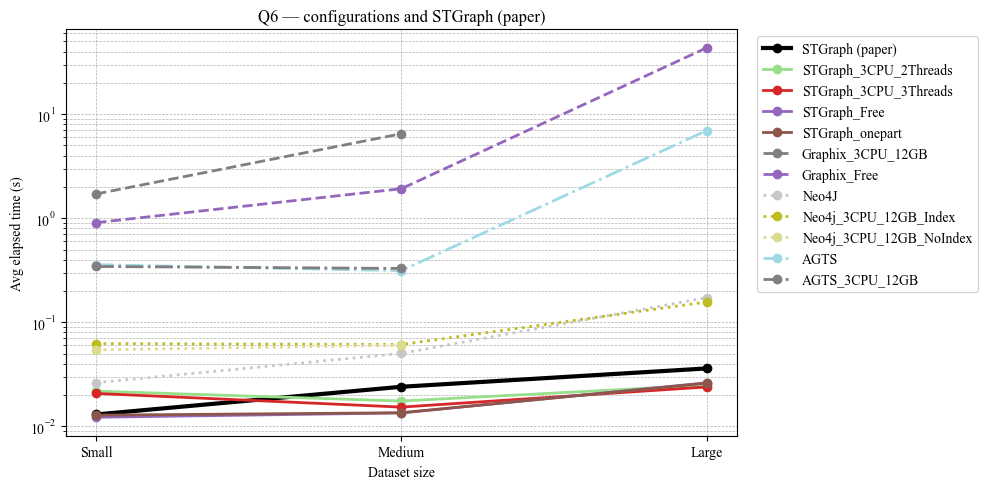

In [21]:
# Come i line chart delle versioni sopra: per ogni query il tempo medio per dimensione, con le configurazioni non
# nascoste (hidden_configurations) e STGraph del paper (nero). Stesso colore per la stessa configurazione: linea
# continua STGraph, tratteggiata Graphix, punteggiata Neo4j, tratto-punto AGTS
shown_configurations = [m for m in configurations if m in query_speedup.columns and m not in hidden_configurations]
avg_by_size = (
    configurations_query_df.assign(datasetSize=configurations_query_df["datasetSize"].astype(str))
    .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean()
)
for query in sorted(configurations_query_df["queryid"].unique()):
    fig, ax = plt.subplots(figsize=(10, 5))
    for model in ["STGraph"] + shown_configurations:
        y = [avg_by_size.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        if model == "STGraph":
            ax.plot(dataset_order, y, marker="o", linewidth=3, color="black", label="STGraph (paper)")
        else:
            ax.plot(dataset_order, y, marker="o", linewidth=2, color=configuration_colors[model],
                    linestyle="-" if model.startswith("STGraph") else ("--" if model.startswith("Graphix")
                    else ("-." if model.startswith("AGTS") else ":")), label=model)
    ax.set_title(f"{query} — configurations and STGraph (paper)")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Avg elapsed time (s)")
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
    plt.tight_layout()
    plt.show()

### Con la mediana delle iterazioni

Gli stessi grafici e la tabella per query con la mediana delle iterazioni al posto della media: robusta alle iterazioni lente a freddo (es. le prime di Neo4j su large). Solo query: l'ingestion ha una sola iterazione per configurazione.

datasetSize,Small,Medium,Large
model,,,
AGTS,4.11,7.32,4.84
AGTS_3CPU_12GB,1.90,3.09,13.51
Graphix_3CPU_12GB,3.19,6.19,NaN
Graphix_Free,1.18,1.71,5.65
Neo4J,1.71,2.09,4.66
Neo4j_3CPU_12GB_Index,0.51,0.86,4.48
Neo4j_3CPU_12GB_NoIndex,1.01,2.14,NaN
STGraph_3CPU_2Threads,1.03,0.86,0.81
STGraph_3CPU_3Threads,0.97,0.80,0.72


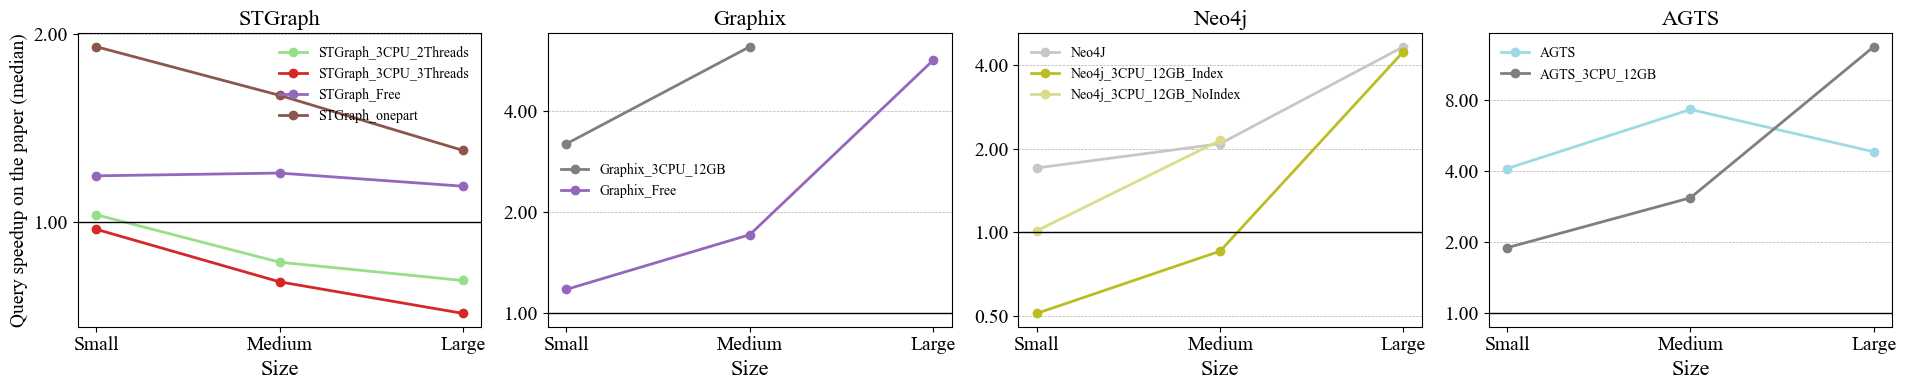

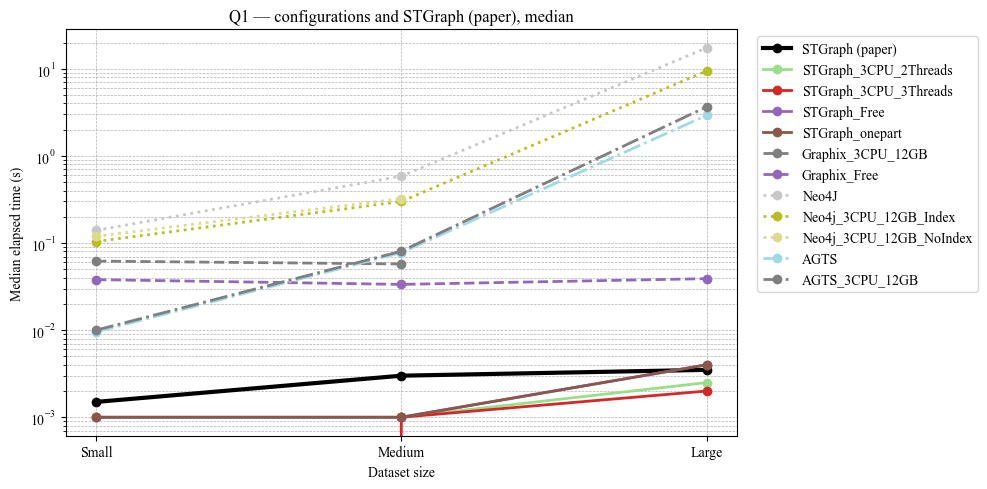

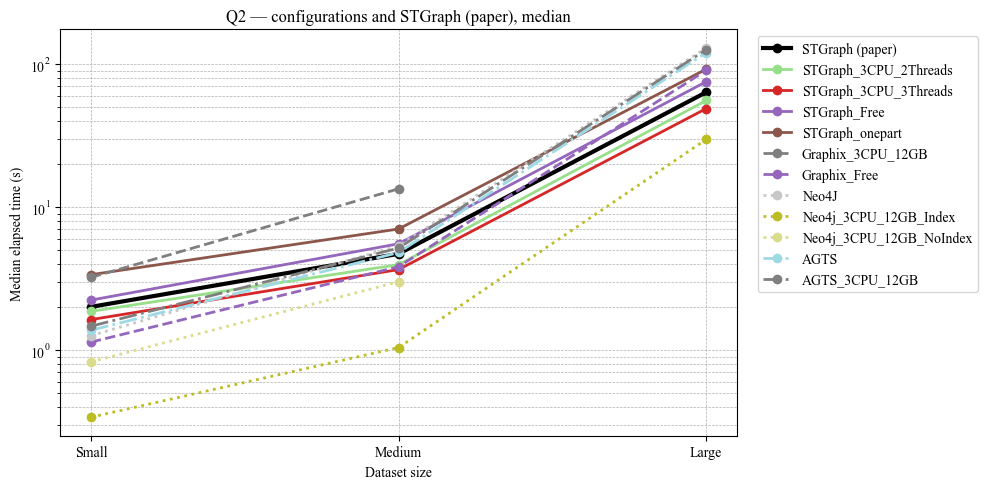

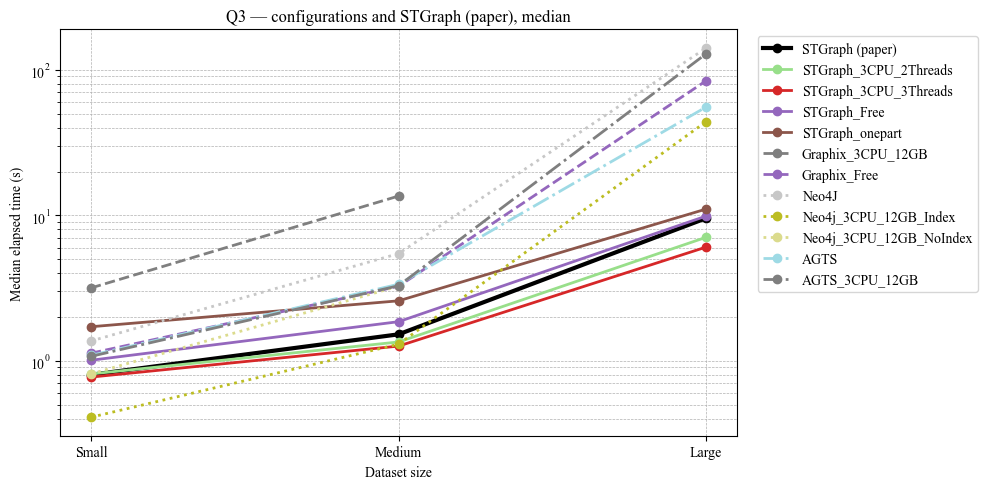

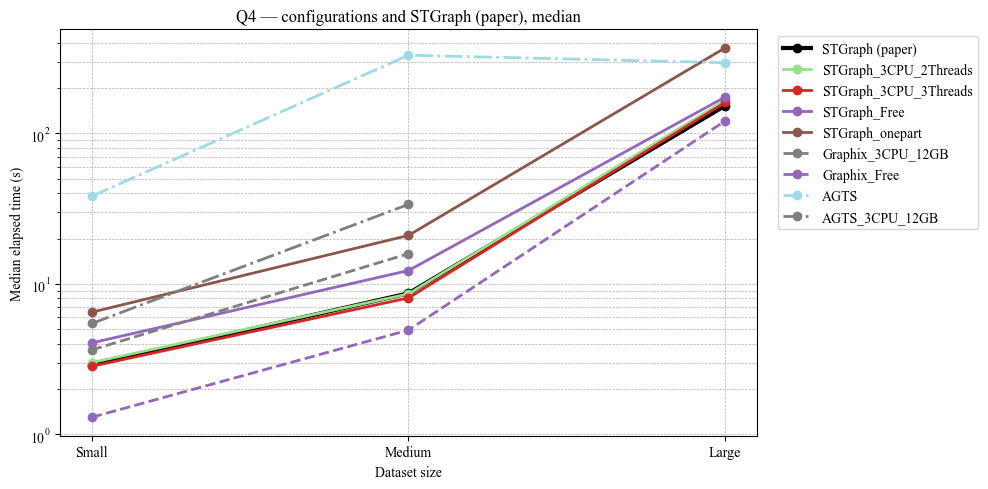

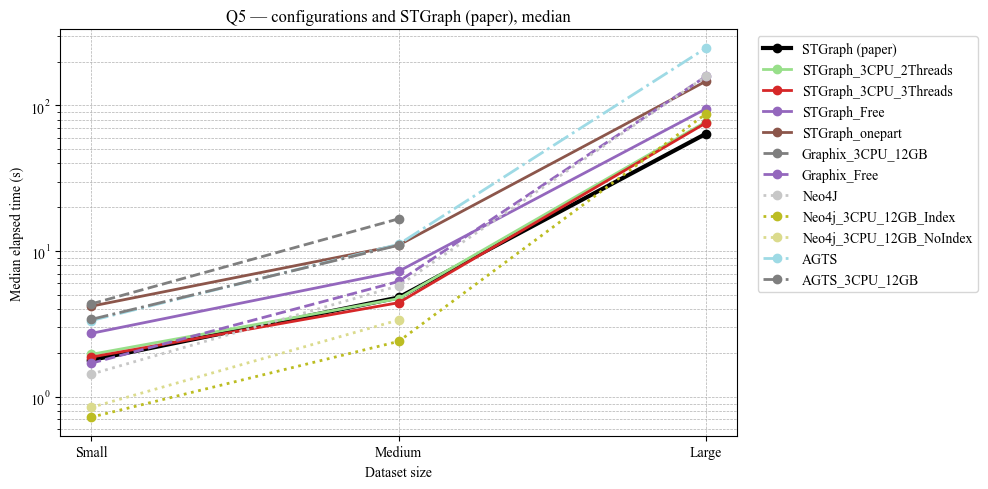

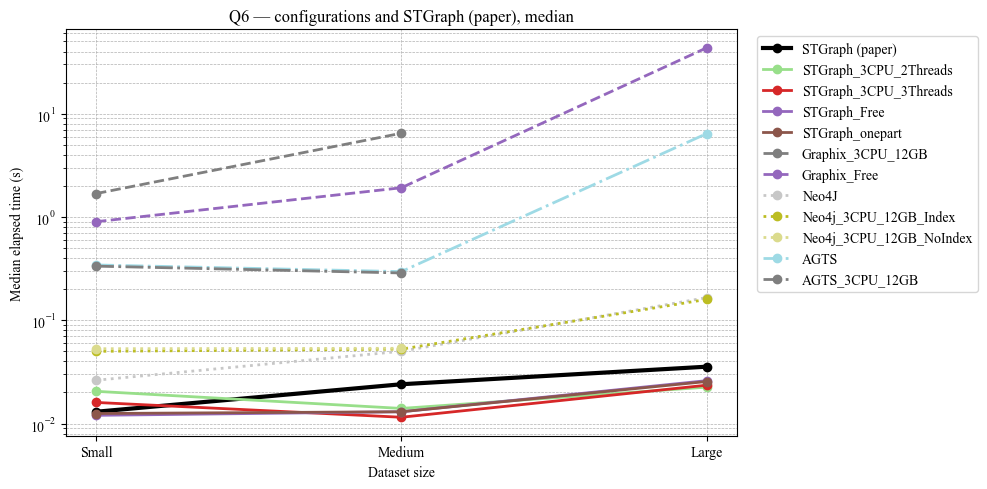

datasetSize              Small                                   Medium        \
queryid                     Q1    Q2    Q3     Q4    Q5      Q6      Q1    Q2   
model                                                                           
AGTS                      6.36  0.69  1.36  13.30  1.87   26.38   25.90  1.02   
AGTS_3CPU_12GB            6.67  0.73  1.34   1.90  1.90   25.69   26.83  1.10   
Graphix_3CPU_12GB        41.33  1.61  3.95   1.26  2.43  129.58   19.17  2.85   
Graphix_Free             25.33  0.57  1.41   0.45  0.95   69.23   11.17  0.81   
Neo4J                    93.21  0.63  1.71    NaN  0.80    2.02  195.19  1.14   
Neo4j_3CPU_12GB_Index    69.33  0.17  0.51    NaN  0.41    3.85  100.00  0.22   
Neo4j_3CPU_12GB_NoIndex  79.67  0.41  1.01    NaN  0.47    4.08  107.83  0.64   
STGraph_3CPU_2Threads     0.67  0.93  1.01   1.04  1.09    1.58    0.33  0.84   
STGraph_3CPU_3Threads     0.00  0.81  0.96   0.99  1.05    1.23    0.33  0.78   
STGraph_Free              0.67  1.12  1.26   1.41  1.53    0.92    0.33  1.18   
STGraph_onepart           0.67  1.68  2.14   2.25  2.34    0.96    0.33  1.49   

datasetSize                                           Large               \
queryid                    Q3     Q4    Q5      Q6       Q1    Q2     Q3   
model                                                                      
AGTS                     2.21  38.18  2.32   12.32   833.68  1.89   5.81   
AGTS_3CPU_12GB           2.16   3.90  2.28   11.96  1045.14  1.99  13.51   
Graphix_3CPU_12GB        8.92   1.83  3.47  269.42      NaN   NaN    NaN   
Graphix_Free             2.14   0.57  1.29   79.90    11.14  1.42   8.81   
Neo4J                    3.59    NaN  1.20    2.09  4968.46  2.04  14.80   
Neo4j_3CPU_12GB_Index    0.86    NaN  0.50    2.19  2700.00  0.47   4.62   
Neo4j_3CPU_12GB_NoIndex  2.14    NaN  0.70    2.23      NaN   NaN    NaN   
STGraph_3CPU_2Threads    0.89   0.99  0.98    0.58     0.71  0.87   0.74   
STGraph_3CPU_3Threads    0.83   0.93  0.92    0.48     0.57  0.77   0.63   
STGraph_Free             1.22   1.42  1.51    0.54     1.14  1.19   1.03   
STGraph_onepart          1.70   2.42  2.28    0.54     1.14  1.45   1.16   

datasetSize                                   
queryid                    Q4    Q5       Q6  
model                                         
AGTS                     1.93  3.87   180.45  
AGTS_3CPU_12GB            NaN   NaN      NaN  
Graphix_3CPU_12GB         NaN   NaN      NaN  
Graphix_Free             0.79  2.48  1221.87  
Neo4J                     NaN  2.48     4.66  
Neo4j_3CPU_12GB_Index     NaN  1.37     4.48  
Neo4j_3CPU_12GB_NoIndex   NaN   NaN      NaN  
STGraph_3CPU_2Threads    1.08  1.21     0.63  
STGraph_3CPU_3Threads    1.05  1.19     0.66  
STGraph_Free             1.14  1.48     0.73  
STGraph_onepart          2.42  2.29     0.72

In [22]:
query_speedup_median = speed_up_by_size(configurations_query_df, ["datasetSize", "queryid"], agg="median")
display(query_speedup_median.drop(columns=hidden_configurations, errors="ignore").T.round(2))

panels = []
for system, models in [("STGraph", stgraph_configurations), ("Graphix", graphix_configurations), ("Neo4j", neo4j_configurations), ("AGTS", agts_configurations)]:
    shown = [m for m in models if m in query_speedup_median.columns and query_speedup_median[m].notna().any() and m not in hidden_configurations]
    if shown:
        panels.append((system, shown))
fig, axes = plt.subplots(1, len(panels), figsize=(fig_x * 1.6 * len(panels), fig_y * 1.6), squeeze=False)
for ax, (system, shown) in zip(axes[0], panels):
    for model in shown:
        ax.plot(dataset_order, query_speedup_median[model].values, marker="o", linewidth=2, color=configuration_colors[model], label=model)
    ax.axhline(1, color="black", linewidth=1)  # STGraph del paper
    ax.set_yscale("log", base=2)
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_title(system, fontsize=font)
    ax.set_xlabel("Size", fontsize=font)
    ax.tick_params(labelsize=font - 2)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    ax.legend(fontsize=font - 6, frameon=False)
axes[0][0].set_ylabel("Query speedup on the paper (median)", fontsize=font - 2)
plt.tight_layout()
plt.show()

# Per query: il tempo mediano per dimensione, come i line chart sopra
median_by_size = (
    configurations_query_df.assign(datasetSize=configurations_query_df["datasetSize"].astype(str))
    .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].median()
)
for query in sorted(configurations_query_df["queryid"].unique()):
    fig, ax = plt.subplots(figsize=(10, 5))
    for model in ["STGraph"] + shown_configurations:
        y = [median_by_size.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        if model == "STGraph":
            ax.plot(dataset_order, y, marker="o", linewidth=3, color="black", label="STGraph (paper)")
        else:
            ax.plot(dataset_order, y, marker="o", linewidth=2, color=configuration_colors[model],
                    linestyle="-" if model.startswith("STGraph") else ("--" if model.startswith("Graphix")
                    else ("-." if model.startswith("AGTS") else ":")), label=model)
    ax.set_title(f"{query} — configurations and STGraph (paper), median")
    ax.set_xlabel("Dataset size")
    ax.set_ylabel("Median elapsed time (s)")
    ax.set_yscale("log")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
    plt.tight_layout()
    plt.show()

# Speedup per query con la mediana: ogni variante non nascosta / STGraph del paper
median = configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["elapsedTime"].median().unstack("model")
display(median.drop(columns="STGraph").div(median["STGraph"], axis=0).drop(columns=hidden_configurations, errors="ignore").T.round(2))

### Line chart per query, versione zoomata

Gli stessi line chart per query (media e mediana), più leggibili: l'asse y tagliato tra il 10° e il 90° percentile dei tempi del grafico (i punti fuori dal taglio restano segnati al bordo, con una freccia e il loro valore), colori distinti tra le sole configurazioni graficate, un tratto e un marcatore per sistema (continuo e cerchio STGraph, tratteggiato e quadrato Graphix, punteggiato e triangolo Neo4j, tratto-punto e rombo AGTS) e le linee leggermente sfalsate in orizzontale.

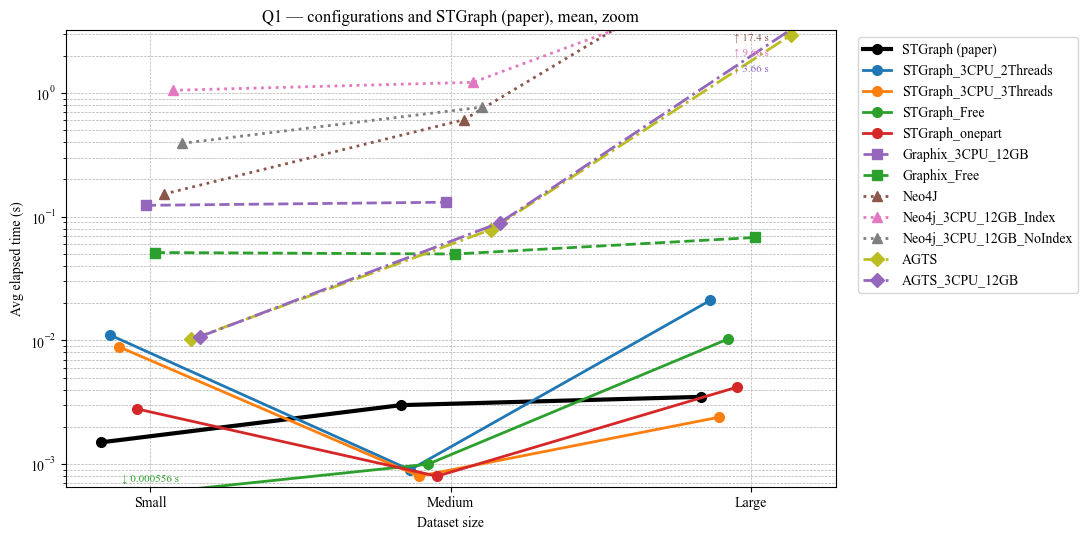

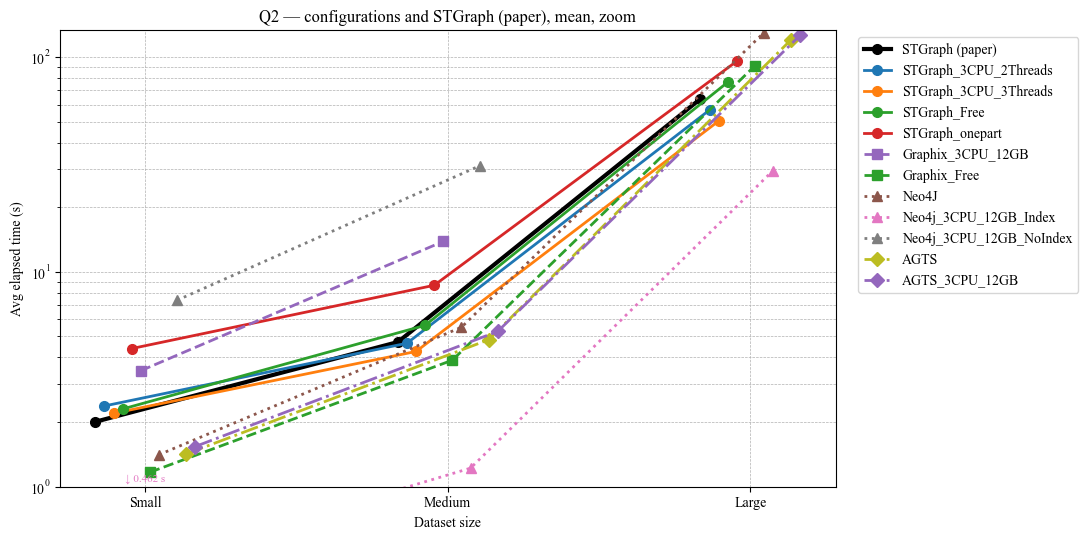

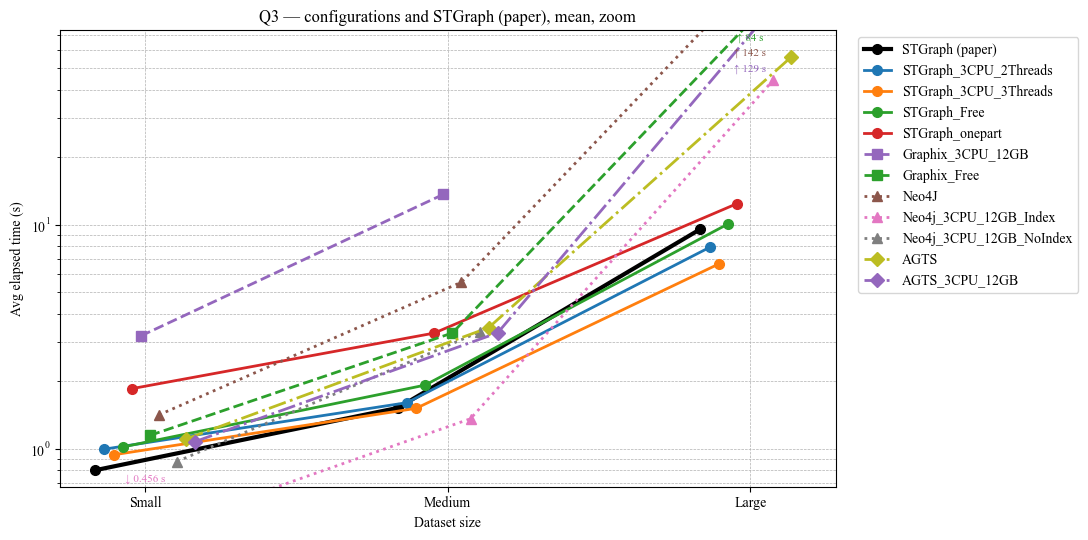

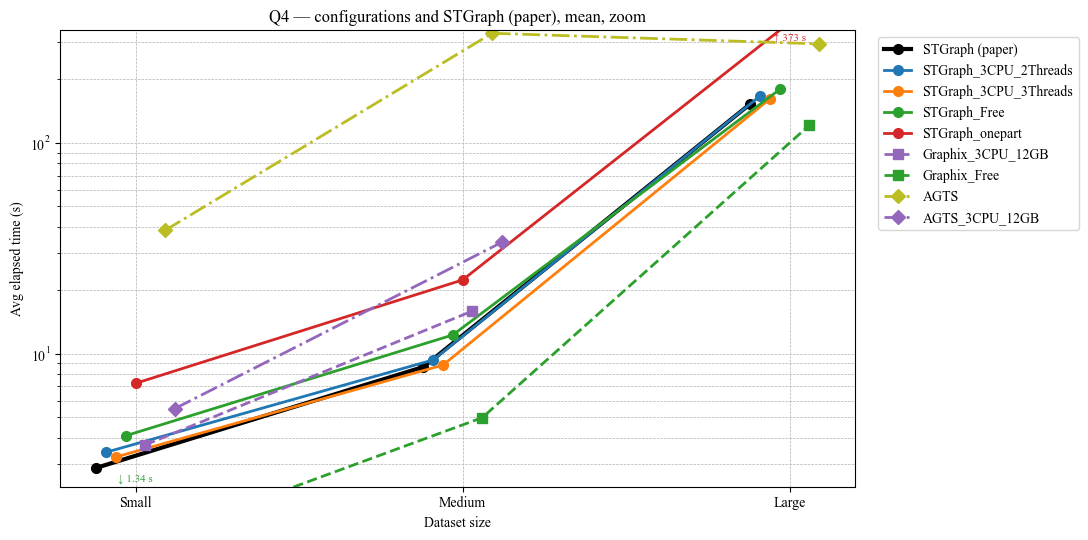

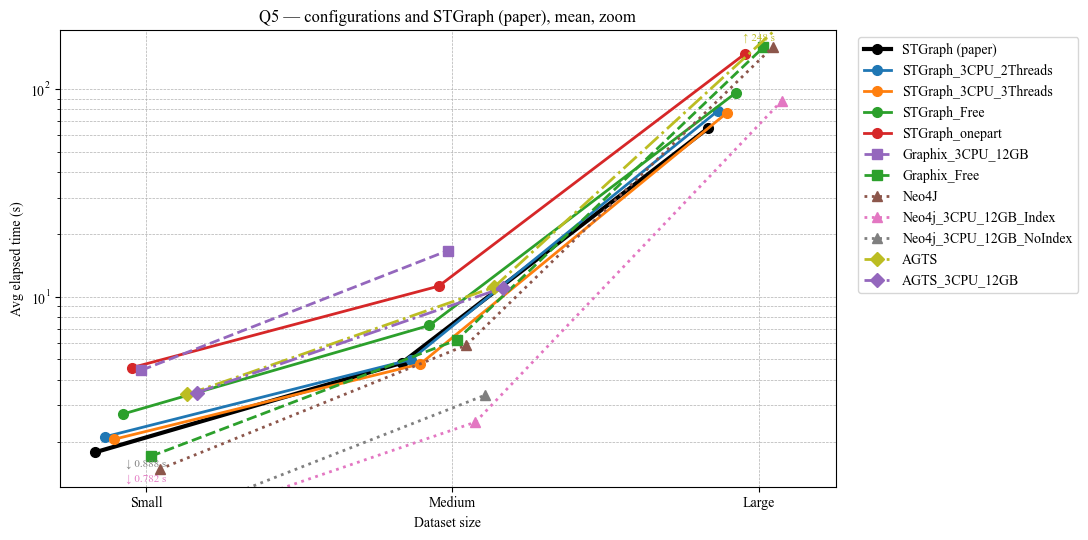

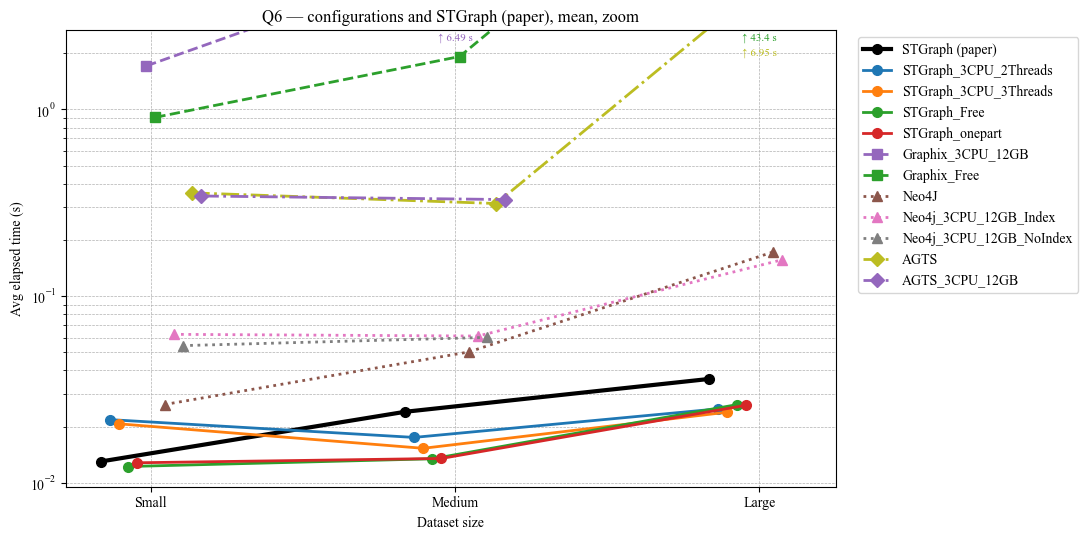

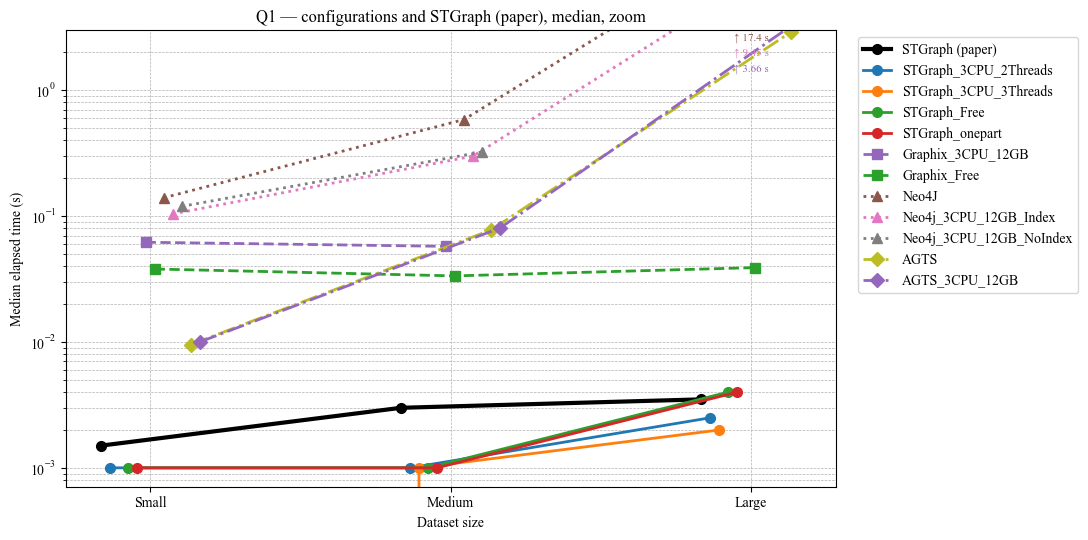

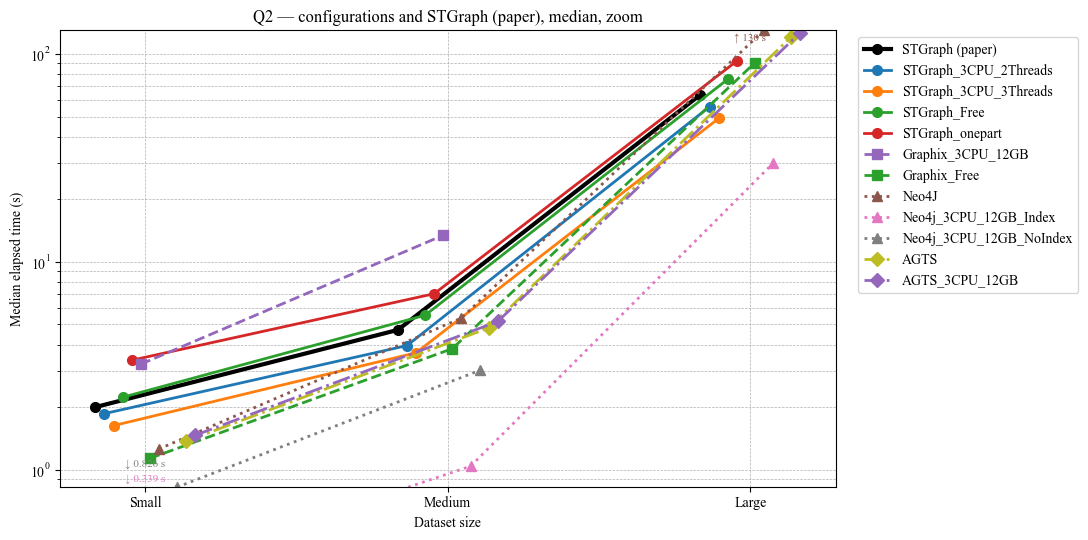

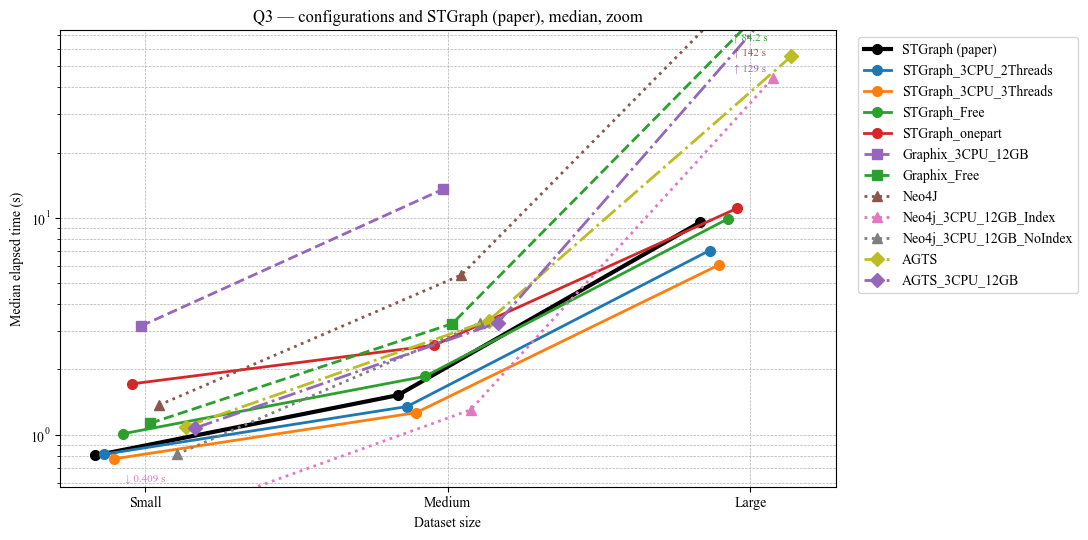

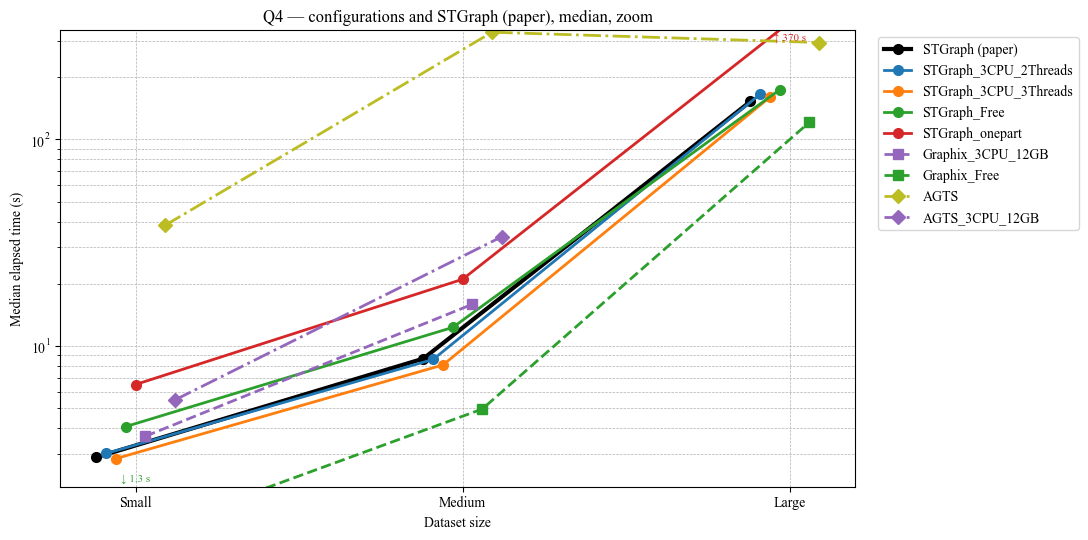

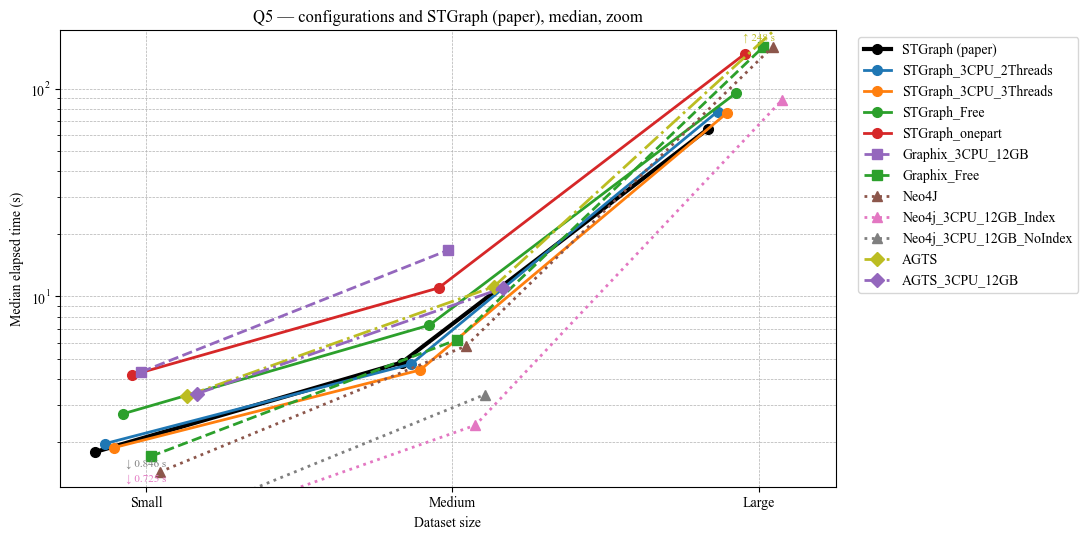

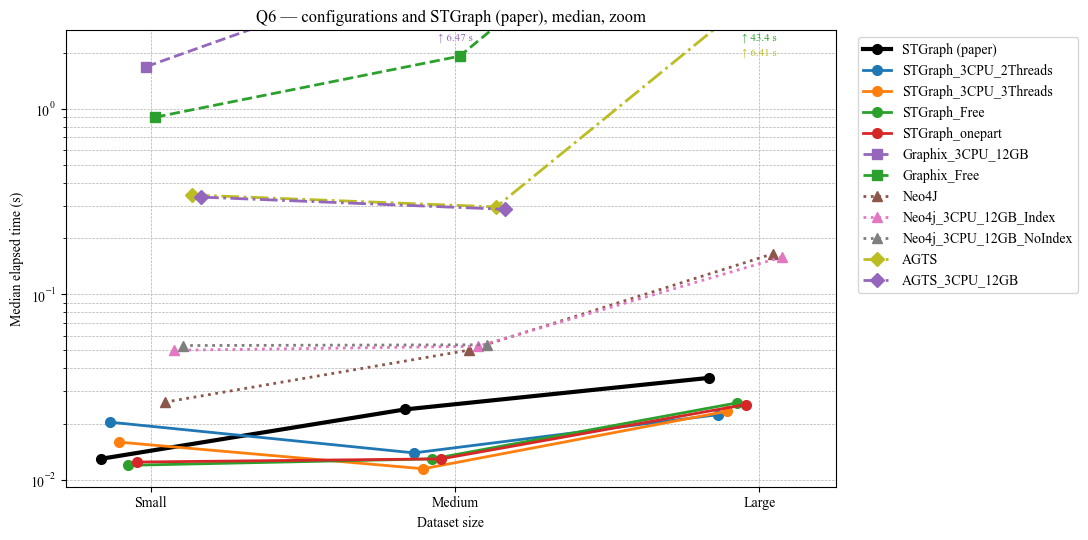

In [23]:
zoom_palette = plt.get_cmap("tab10").colors
zoom_names = list(dict.fromkeys(configuration(m) for m in shown_configurations))
zoom_colors = {m: zoom_palette[zoom_names.index(configuration(m)) % len(zoom_palette)] for m in shown_configurations}
zoom_colors["STGraph"] = "black"
zoom_styles = {"STGraph": ("-", "o"), "Graphix": ("--", "s"), "Neo4j": (":", "^"), "AGTS": ("-.", "D")}

def zoom_system(model):
    if model.startswith("AGTS"):
        return "AGTS"
    return "Graphix" if model.startswith("Graphix") else ("Neo4j" if model.lower().startswith("neo4j") else "STGraph")

def plot_query_lines_zoomed(values_by_size, what):
    """I line chart per query di values_by_size (query, dimensione, modello -> secondi), tagliati tra il 10° e il 90°
    percentile dei loro tempi"""
    x = np.arange(len(dataset_order))
    for query in sorted(configurations_query_df["queryid"].unique()):
        lines = {m: np.array([values_by_size.get((query, size, m), np.nan) for size in dataset_order]) for m in ["STGraph"] + shown_configurations}
        lines = {m: y for m, y in lines.items() if not np.all(np.isnan(y))}
        values = np.concatenate([y[~np.isnan(y)] for y in lines.values()])
        values = values[values > 0]
        low, high = np.percentile(np.log10(values), [10, 90])
        low, high = 10 ** (low - 0.15), 10 ** (high + 0.15)
        fig, ax = plt.subplots(figsize=(11, 5.5))
        clipped = {}  # le etichette già al bordo, per dimensione: le successive vanno sotto (sopra) le precedenti
        for i, (model, y) in enumerate(lines.items()):
            xs = x + (i - (len(lines) - 1) / 2) * 0.03
            linestyle, marker = zoom_styles[zoom_system(model)]
            ax.plot(xs, y, marker=marker, markersize=7, linewidth=3 if model == "STGraph" else 2, color=zoom_colors[model],
                    linestyle=linestyle, label="STGraph (paper)" if model == "STGraph" else model)
            for j, (xi, yi) in enumerate(zip(xs, y)):  # i punti fuori dal taglio: al bordo, con una freccia e il valore
                if yi > high or 0 < yi < low:
                    side = "top" if yi > high else "bottom"
                    k = clipped.get((j, side), 0)
                    clipped[(j, side)] = k + 1
                    ax.annotate(f"{chr(0x2191) if side == 'top' else chr(0x2193)} {yi:.3g} s", (x[j], high if side == "top" else low),
                                xytext=(0, -11 * k - 2 if side == "top" else 11 * k + 2), textcoords="offset points",
                                fontsize=8, color=zoom_colors[model], ha="center", va=side)
        ax.set_yscale("log")
        ax.set_ylim(low, high)
        ax.set_xticks(x, dataset_order)
        ax.set_title(f"{query} — configurations and STGraph (paper), {what}, zoom")
        ax.set_xlabel("Dataset size")
        ax.set_ylabel(f"{'Avg' if what == 'mean' else 'Median'} elapsed time (s)")
        ax.grid(True, which="both", linestyle="--", linewidth=0.5)
        ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
        plt.tight_layout()
        plt.show()

plot_query_lines_zoomed(avg_by_size, "mean")
plot_query_lines_zoomed(median_by_size, "median")

In [24]:
# Speedup per query: ogni variante non nascosta, Graphix e Neo4j compresi, / STGraph del paper
avg = configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().unstack("model")
display(avg.drop(columns="STGraph").div(avg["STGraph"], axis=0).drop(columns=hidden_configurations, errors="ignore").T.round(2))

datasetSize               Small                                   Medium  \
queryid                      Q1    Q2    Q3     Q4    Q5      Q6      Q1   
model                                                                      
AGTS                       6.79  0.71  1.38  13.35  1.90   27.49   26.22   
AGTS_3CPU_12GB             7.13  0.77  1.34   1.91  1.93   26.45   29.87   
Graphix_3CPU_12GB         82.27  1.73  3.97   1.29  2.48  131.58   43.60   
Graphix_Free              34.20  0.58  1.43   0.47  0.95   69.79   16.63   
Neo4J                    101.31  0.70  1.76    NaN  0.83    2.02  202.52   
Neo4j_3CPU_12GB_Index    699.40  0.23  0.57    NaN  0.44    4.80  405.83   
Neo4j_3CPU_12GB_NoIndex  260.60  3.68  1.09    NaN  0.50    4.18  255.73   
STGraph_3CPU_2Threads      7.40  1.18  1.24   1.19  1.19    1.68    0.30   
STGraph_3CPU_3Threads      5.93  1.09  1.17   1.13  1.15    1.59    0.27   
STGraph_Free               0.37  1.15  1.27   1.42  1.53    0.94    0.33   
STGraph_onepart            1.87  2.19  2.31   2.52  2.56    0.98    0.27   

datasetSize                                                 Large        \
queryid                    Q2    Q3     Q4    Q5      Q6       Q1    Q2   
model                                                                     
AGTS                     1.03  2.28  38.20  2.31   13.05   843.48  1.89   
AGTS_3CPU_12GB           1.12  2.16   3.90  2.30   13.71  1045.14  1.98   
Graphix_3CPU_12GB        2.94  8.96   1.84  3.47  270.29      NaN   NaN   
Graphix_Free             0.82  2.16   0.58  1.29   80.04    19.40  1.43   
Neo4J                    1.17  3.64    NaN  1.22    2.09  4957.67  2.04   
Neo4j_3CPU_12GB_Index    0.26  0.89    NaN  0.52    2.55  2759.43  0.46   
Neo4j_3CPU_12GB_NoIndex  6.61  2.18    NaN  0.70    2.50      NaN   NaN   
STGraph_3CPU_2Threads    0.99  1.05   1.08  1.04    0.73     6.03  0.89   
STGraph_3CPU_3Threads    0.90  0.99   1.02  0.99    0.64     0.69  0.79   
STGraph_Free             1.20  1.26   1.42  1.51    0.56     2.94  1.20   
STGraph_onepart          1.84  2.16   2.59  2.34    0.56     1.20  1.50   

datasetSize                                          
queryid                     Q3    Q4    Q5       Q6  
model                                                
AGTS                      5.85  1.92  3.83   192.95  
AGTS_3CPU_12GB           13.54   NaN   NaN      NaN  
Graphix_3CPU_12GB          NaN   NaN   NaN      NaN  
Graphix_Free              8.81  0.79  2.45  1205.01  
Neo4J                    14.88   NaN  2.45     4.79  
Neo4j_3CPU_12GB_Index     4.61   NaN  1.35     4.35  
Neo4j_3CPU_12GB_NoIndex    NaN   NaN   NaN      NaN  
STGraph_3CPU_2Threads     0.83  1.09  1.21     0.69  
STGraph_3CPU_3Threads     0.70  1.06  1.18     0.66  
STGraph_Free              1.05  1.17  1.48     0.73  
STGraph_onepart           1.30  2.43  2.28     0.72

### Le configurazioni a 3 CPU contro le baseline Free

Un line chart per query con le sole configurazioni a 3 CPU (tranne quelle di `hidden_configurations`) e la baseline Free del loro sistema, cioè senza limiti di risorse: il tempo medio per dimensione. Colore per sistema (STGraph in nero); linea continua e marcatore pieno a 3 CPU, tratteggiata e marcatore vuoto la Free. Solo STGraph e Graphix hanno un'esecuzione Free: Neo4j e AGTS compaiono solo a 3 CPU.

Righe per configurazione e dimensione


datasetSize,Small,Medium,Large
model,,,
STGraph_Free,54,54,60
STGraph_3CPU_2Threads,60,60,60
STGraph_3CPU_3Threads,60,60,60
Graphix_Free,60,60,60
Graphix_3CPU_12GB,60,60,0
Neo4j_3CPU_12GB_Index,50,50,50
Neo4j_3CPU_12GB_NoIndex,50,50,0
AGTS_3CPU_12GB,60,60,3


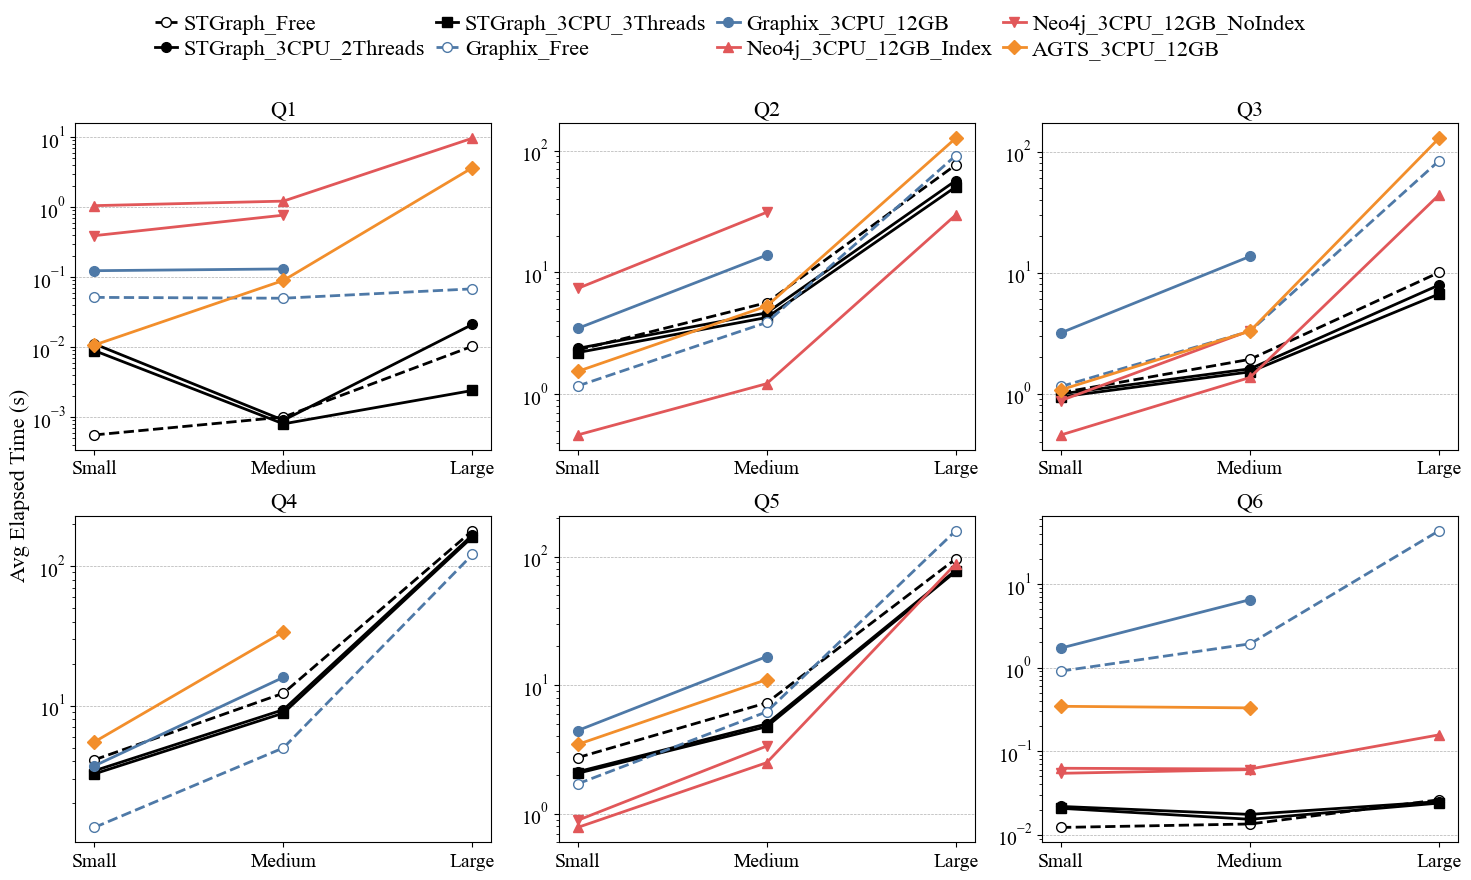

In [25]:
cpu3_order = ["STGraph", "Graphix", "Neo4j", "AGTS"]

def cpu3_system(model):
    return model.split("_", 1)[0]

cpu3_models = sorted(
    [m for m in configurations if m.endswith("_Free")]
    + [m for m in configurations if "3CPU" in m and m not in hidden_configurations],
    key=lambda m: (cpu3_order.index(cpu3_system(m)), not m.endswith("_Free"), m))
cpu3_colors = {"STGraph": "black", "Graphix": tableau10[0], "Neo4j": tableau10[2], "AGTS": tableau10[1]}
cpu3_markers = {"STGraph_3CPU_2Threads": "o", "STGraph_3CPU_3Threads": "s", "Neo4j_3CPU_12GB_Index": "^",
                "Neo4j_3CPU_12GB_NoIndex": "v", "AGTS_3CPU_12GB": "D"}

cpu3_df = configurations_query_df[configurations_query_df["model"].isin(cpu3_models)]
print("Righe per configurazione e dimensione")
display(cpu3_df.groupby(["model", "datasetSize"], observed=True).size().unstack(fill_value=0)
        .reindex(index=cpu3_models, columns=dataset_order, fill_value=0))

cpu3_avg = (cpu3_df.assign(datasetSize=cpu3_df["datasetSize"].astype(str))
            .groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean())
cpu3_queries = sorted(cpu3_df["queryid"].unique())
fig, axes = plt.subplots(2, 3, figsize=(fig_x * 5, fig_y * 3.2), squeeze=False)
for ax, query in zip(axes.flat, cpu3_queries):
    for model in cpu3_models:
        y = [cpu3_avg.get((query, size, model), np.nan) for size in dataset_order]
        if np.all(np.isnan(y)):
            continue
        is_free = model.endswith("_Free")
        color = cpu3_colors[cpu3_system(model)]
        ax.plot(dataset_order, y, marker=cpu3_markers.get(model, "o"), markersize=7, linewidth=2, color=color,
                linestyle="--" if is_free else "-", markerfacecolor="white" if is_free else color, label=model)
    ax.set_yscale("log")
    ax.set_title(query, fontsize=font)
    ax.tick_params(labelsize=font - 2)
    ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
for ax in axes.flat[len(cpu3_queries):]:
    ax.axis("off")
fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
fig.legend(handles.values(), handles.keys(), ncol=4, **legend_settings)
plt.tight_layout()
os.makedirs(os.path.join(figures_path, "3cpu_free"), exist_ok=True)
plt.savefig(os.path.join(figures_path, "3cpu_free", "query_lines_smartbench.pdf"), bbox_inches="tight")
plt.show()

In [26]:
# Controlli: cardinalità diverse da quella della maggior parte delle esecuzioni (paper compreso), ed esecuzioni
# (test_id) registrate sotto due varianti
card = (configurations_query_df.groupby(["datasetSize", "queryid", "model"], observed=True)["cardinality"]
        .agg(lambda s: "/".join(str(int(v)) for v in sorted(s.unique()))).reset_index())
card["expected"] = card.groupby(["datasetSize", "queryid"], observed=True)["cardinality"].transform(lambda s: s.mode().iloc[0])
display(card[card["cardinality"] != card["expected"]])

for name, df in [("query", query_statistics), ("ingestion", ingestion_statistics)]:
    shared = df[df["dataset"] == "smartbench"].groupby("test_id")["model"].agg(lambda s: ", ".join(sorted(set(s))))
    print(name, shared[shared.str.contains(", ")].value_counts().to_dict())

,datasetSize,queryid,model,cardinality,expected
167,Medium,Q1,STGraph,20,22
193,Medium,Q2,STGraph,90,95
241,Medium,Q4,STGraph,5,3
309,Large,Q1,Graphix_2Part,22/131,131
330,Large,Q2,Graphix_2Part,0/112,112
351,Large,Q3,Graphix_2Part,200/1000,1000
371,Large,Q4,Graphix_2Part,3/5,5
388,Large,Q5,Graphix_2Part,200/1000,1000
413,Large,Q6,Neo4J,0,1


query {'STGraph_2Part, STGraph_opt': 60}
ingestion {'STGraph_1Part, STGraph_1Part_1Cpu_Conf': 3, 'AeonG, HyGraph, Neo4J': 1, 'Graphix_1Part_No_index, Graphix_2Part_No_index': 1, 'STGraph_2Part, STGraph_opt': 1}


## Confronto con i sistemi del paper: STGraph su una partizione con 1 CPU

Le tabelle del paper (tempi di query e ingestion, rapporti sugli altri sistemi), un line chart per query e il grafico dell'ingestion del paper, con STGraph su una partizione con 1 CPU come riferimento (lo STGraph del paper resta per confronto, tratteggiato nei line chart), Graphix nella stessa configurazione e gli altri sistemi (Neo4J, AGTS, AeonG, HyGraph) con i valori del paper. Solo SmartBench: le configurazioni ci sono solo lì. Le figure vanno in `figures/<configurazione>/`, quelle del paper restano come sono.

Query, righe per sistema e dimensione


datasetSize,Small,Medium,Large
model,,,
AGTS,170,170,110
AeonG,475,467,0
Graphix,60,60,120
HyGraph,65,115,0
Neo4J,160,60,80
STGraph,60,60,62
STGraph (paper),12,12,36


Ingestion, esecuzioni per sistema e dimensione


datasetSize,Small,Medium,Large
model,,,
AGTS,21,2,3
AeonG,5,5,1
Graphix,2,2,2
HyGraph,5,6,1
Neo4J,1,1,1
STGraph,1,1,2
STGraph (paper),1,1,1


\begin{tabular}{llllllllll}
\toprule
 &  & Model & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph & STGraph (paper) \\
dataset & Size & ID &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{24}{*}{smartbench} & \multirow[t]{6}{*}{--} & Q1 & -- & -- & -- & -- & -- & -- & $3.5 \cdot 10^{-3}$ \\
 &  & Q2 & -- & -- & -- & -- & -- & -- & $1.6 \cdot 10^{2}$ \\
 &  & Q3 & -- & -- & -- & -- & -- & -- & $1.3 \cdot 10^{1}$ \\
 &  & Q4 & -- & -- & -- & -- & -- & -- & $9.5 \cdot 10^{2}$ \\
 &  & Q5 & -- & -- & -- & -- & -- & -- & $1.4 \cdot 10^{2}$ \\
 &  & Q6 & -- & -- & -- & -- & -- & -- & $4.4 \cdot 10^{-2}$ \\
\cline{2-10}
 & \multirow[t]{6}{*}{S} & Q1 & $1.0 \cdot 10^{-2}$ & $1.3 \cdot 10^{-2}$ & $1.2 \cdot 10^{-1}$ & $6.3 \cdot 10^{-2}$ & $1.5 \cdot 10^{-1}$ & $2.8 \cdot 10^{-3}$ & $1.5 \cdot 10^{-3}$ \\
 &  & Q2 & $1.4 \cdot 10^{0}$ & $8.0 \cdot 10^{1}$ & $4.0 \cdot 10^{0}$ & $7.2 \cdot 10^{2}$ & $1.4 \cdot 10^{0}$ & $4.4 \cdot 10^{0}$ & $2.0 \cdot 10^{0}$ \\
 &  & Q3 & $1.1 \cdot 10^{0}$ & 

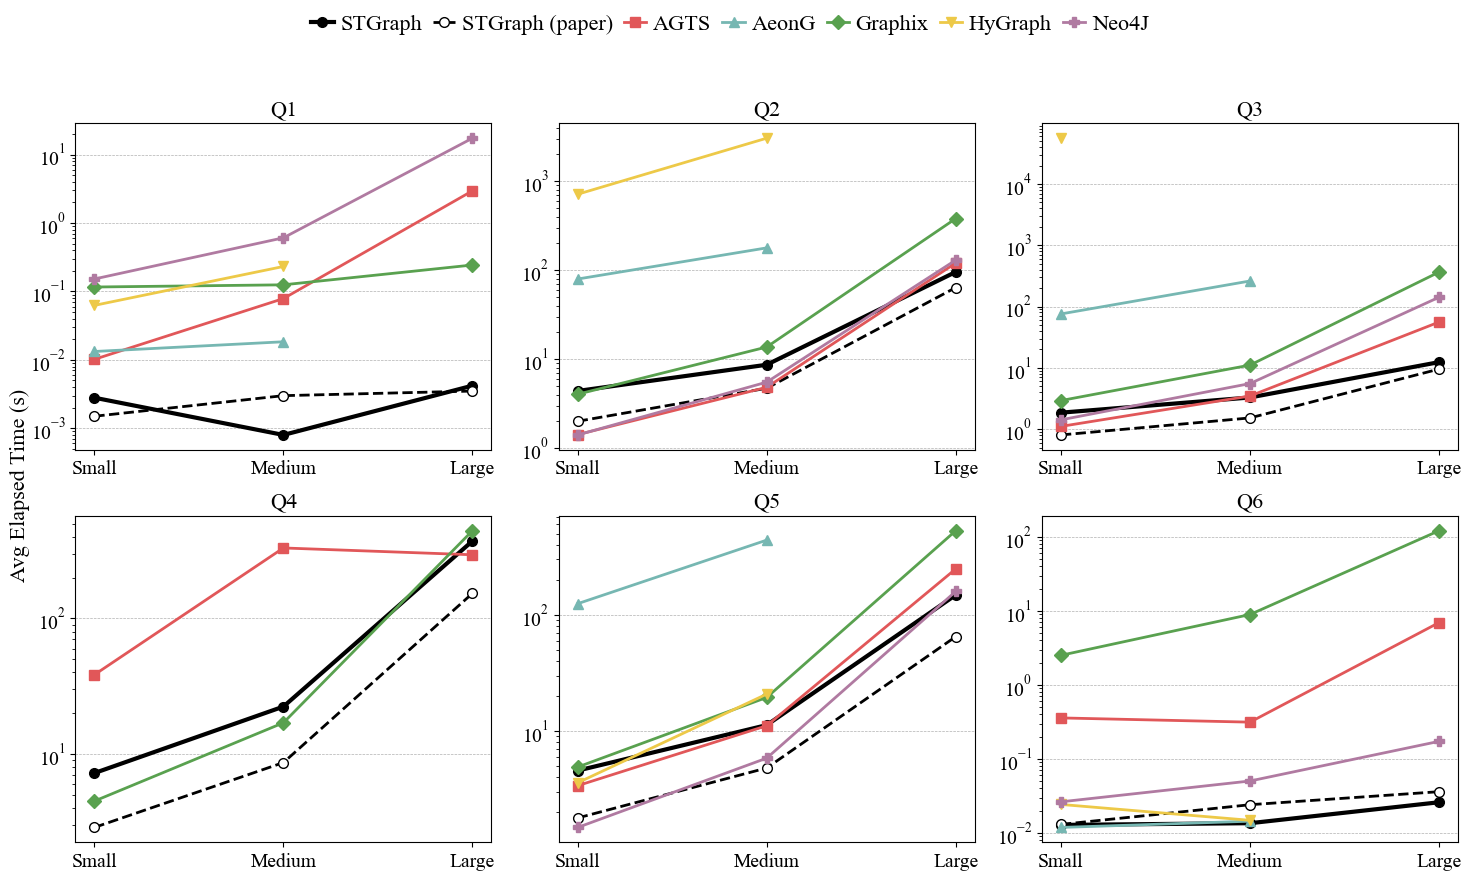

Query: tempo / STGraph, media troncata sulle query
\begin{tabular}{llrrrrrr}
\toprule
 &  & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.2 & 18.1 & 1.3 & 22.3 & 0.8 & 0.4 \\
 & M & 7.9 & 23.0 & 2.6 & 145.6 & 1.7 & 0.5 \\
 & L & 3.1 & -- & 16.8 & -- & 6.7 & 0.7 \\
\cline{1-8}
\bottomrule
\end{tabular}

\begin{tabular}{lllllllll}
\toprule
 & Model & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & $8.4 \cdot 10^{1}$ & $0$ & $2.9 \cdot 10^{1}$ & -- & $4.3 \cdot 10^{4}$ & $3.6 \cdot 10^{1}$ & $1.3 \cdot 10^{1}$ \\
 & M & $6.2 \cdot 10^{2}$ & $0$ & $1.1 \cdot 10^{2}$ & -- & -- & $1.3 \cdot 10^{2}$ & $5.3 \cdot 10^{1}$ \\
 & L & $1.2 \cdot 10^{5}$ & -- & $3.6 \cdot 10^{3}$ & -- & -- & $3.2 \cdot 10^{3}$ & $1.7 \cdot 10^{3}$ \\
\cline{1-9}
\bottomrule
\end{tabular}



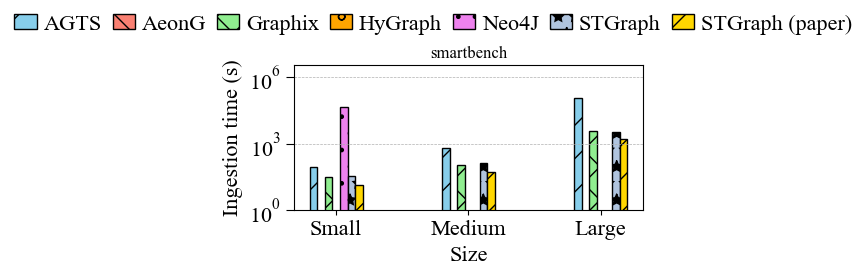

Ingestion: tempo / STGraph
\begin{tabular}{llrrrrrr}
\toprule
 &  & AGTS & AeonG & Graphix & HyGraph & Neo4J & STGraph (paper) \\
dataset & Size &  &  &  &  &  &  \\
\midrule
\multirow[t]{3}{*}{smartbench} & S & 2.4 & 0.0 & 0.8 & -0.0 & 1221.2 & 0.4 \\
 & M & 4.9 & 0.0 & 0.9 & -0.0 & -0.0 & 0.4 \\
 & L & 37.0 & -0.0 & 1.1 & -0.0 & -0.0 & 0.5 \\
\cline{1-8}
\bottomrule
\end{tabular}



In [27]:
# STGraph su una partizione con 1 CPU e Graphix nella stessa configurazione, con la conf del repo (minimo parallelismo).
# I nomi della stessa configurazione si uniscono: nelle query STGraph_1Part_1Cpu (due righe del large, con gli stessi
# tempi di onepart), nell'ingestion STGraph_1Part e STGraph_1Part_1Cpu_Conf (le esecuzioni uguali contano una volta).
# Senza conf (senza limiti di parallelismo e worker) c'è solo 1 CPU, con le 2 partizioni dell'immagine e senza il
# large di STGraph: per usarla, le righe commentate
round_name = "onepart"
round_stgraph = {"query": ["STGraph_onepart", "STGraph_1Part_1Cpu"], "ingestion": ["STGraph_1Part", "STGraph_1Part_1Cpu_Conf"]}
round_graphix = {"query": ["Graphix"], "ingestion": ["Graphix"]}
# round_name = "1cpu_noconf"
# round_stgraph = {"query": ["STGraph_1CPU_NoConf"], "ingestion": ["STGraph_1CPU_NoConf"]}
# round_graphix = {"query": ["Graphix_1CPU_NoConf"], "ingestion": ["Graphix_1CPU_NoConf"]}
# Gli altri sistemi: i valori del paper
paper_systems = ["Neo4J", "AGTS", "AeonG", "HyGraph"]
# E lo STGraph del paper, per confronto
paper_stgraph = "STGraph (paper)"

def round_models(models, kind):
    """I modelli come nel confronto: STGraph e Graphix per le loro configurazioni, gli altri come sono"""
    return models.replace({**{m: "STGraph" for m in round_stgraph[kind]}, **{m: "Graphix" for m in round_graphix[kind]}})

# Query: come il grafico del paper (1 thread, 1 macchina, OPTIMIZED)
round_query_df = clean_df_stats(query_statistics.copy(deep=True), threads=1, numMachines=1, queryMode="OPTIMIZED",
                                queryid=["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"], queryid_exact_match=True)
round_query_df = round_query_df[(round_query_df["dataset"] == "smartbench")
                                & round_query_df["model"].isin(round_stgraph["query"] + round_graphix["query"] + paper_systems + ["STGraph"])].copy()
round_query_df["model"] = round_models(round_query_df["model"].replace({"STGraph": paper_stgraph}), "query")

# Ingestion: le righe grezze, che print_ingestion_statistics pulisce. Gli altri sistemi e lo STGraph del paper con
# numMachines -1, come nel grafico del paper; STGraph e Graphix con numMachines -1 anche loro, perché print_ingestion_statistics tiene solo quelle
names = ingestion_statistics["model"].replace({"PGAge": "AGTS", "pgage": "AGTS", "stgraph": paper_stgraph})
round_ingestion = ingestion_statistics[
    (ingestion_statistics["dataset"] == "smartbench")
    & ((names.isin(paper_systems + [paper_stgraph]) & (ingestion_statistics["numMachines"] == -1))
       | names.isin(round_stgraph["ingestion"] + round_graphix["ingestion"]))
].copy()
round_ingestion["model"] = round_models(names[round_ingestion.index], "ingestion")
round_ingestion["numMachines"] = -1
# Le stesse esecuzioni sotto due nomi (STGraph_1Part e STGraph_1Part_1Cpu_Conf) una volta sola
round_ingestion = round_ingestion.drop_duplicates(subset=[c for c in round_ingestion.columns if c != "test_id"])

print("Query, righe per sistema e dimensione")
display(round_query_df.groupby(["model", "datasetSize"], observed=True).size().unstack(fill_value=0).reindex(columns=dataset_order, fill_value=0))
print("Ingestion, esecuzioni per sistema e dimensione")
display(round_ingestion.groupby(["model", "datasetSize"]).size().unstack(fill_value=0).reindex(columns=dataset_order, fill_value=0))

def plot_round_query_lines(df):
    """Un line chart per query: il tempo medio per dimensione di ogni sistema (STGraph in nero, quello del paper
    tratteggiato e con il marcatore vuoto)"""
    avg = df.assign(datasetSize=df["datasetSize"].astype(str)).groupby(["queryid", "datasetSize", "model"])["elapsedTime"].mean()
    systems = sorted(df["model"].unique(), key=lambda m: (m != "STGraph", m != paper_stgraph, m))
    markers = dict(zip(systems, ["o", "o", "s", "^", "D", "v", "P", "X"]))
    line_colors = {m: "black" if m in ("STGraph", paper_stgraph) else tableau10[i % len(tableau10)] for i, m in enumerate(systems)}
    queries = sorted(df["queryid"].unique())
    fig, axes = plt.subplots(2, 3, figsize=(fig_x * 5, fig_y * 3.2), squeeze=False)
    for ax, query in zip(axes.flat, queries):
        for model in systems:
            y = [avg.get((query, size, model), np.nan) for size in dataset_order]
            if np.all(np.isnan(y)):
                continue
            ax.plot(dataset_order, y, marker=markers[model], markersize=7, linewidth=3 if model == "STGraph" else 2,
                    color=line_colors[model], linestyle="--" if model == paper_stgraph else "-",
                    markerfacecolor="white" if model == paper_stgraph else line_colors[model], label=model)
        ax.set_yscale("log")
        ax.set_title(query, fontsize=font)
        ax.tick_params(labelsize=font - 2)
        ax.yaxis.grid(True, linestyle="--", linewidth=0.5, which="major")
    for ax in axes.flat[len(queries):]:
        ax.axis("off")
    fig.supylabel("Avg Elapsed Time (s)", fontsize=font)
    handles = {label: handle for ax in axes.flat for handle, label in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), ncol=len(handles), **legend_settings)
    plt.tight_layout()
    plt.savefig(os.path.join(figures_path, "query_lines_smartbench.pdf"), bbox_inches="tight")
    plt.show()

# Le figure in figures/<round_name>: le funzioni del paper salvano in figures_path
paper_figures_path = figures_path
figures_path = os.path.join(paper_figures_path, round_name)
os.makedirs(figures_path, exist_ok=True)
try:
    # I tempi delle query, come la tabella del grafico del paper, e un line chart per query
    print_latex(round_query_df.dropna(subset=["elapsedTime"]).groupby(["dataset", "datasetSize", "queryid", "model"], observed=True)["elapsedTime"].mean().reset_index(),
                pivot=["dataset", "Size", "ID"])
    plot_round_query_lines(round_query_df)
    print("Query: tempo / STGraph, media troncata sulle query")
    speed_up(round_query_df, denominator=True)
    print_ingestion_statistics(round_ingestion)
    print("Ingestion: tempo / STGraph")
    speed_up(clean_df(round_ingestion.copy(deep=True), threads=1), group_cols=["dataset", "datasetSize"], column="model", baseline="STGraph", denominator=True)
finally:
    figures_path = paper_figures_path